In [5]:
%cd C:\Mestrado\Graph_Pruning\prodigy

C:\Mestrado\Graph_Pruning\prodigy


c:\Mestrado\Graph_Pruning\.venv_prodigy\lib\site-packages\IPython\core\magics\osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [4]:

from pathlib import Path
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Repositório PRODIGY
PRODIGY_ROOT = Path(r"C:\Mestrado\Graph_Pruning\prodigy")

# Checkpoint da execução de 1 época
CHECKPOINT_PATH = (
    PRODIGY_ROOT
    / "state"
    / "exp1_16_10_2026_03_05_19"
    / "state_dict"
)

print("PyTorch:", torch.__version__)
print("CUDA disponível:", torch.cuda.is_available())
print("Checkpoint existe:", CHECKPOINT_PATH.exists())
print("Caminho:", CHECKPOINT_PATH)


PyTorch: 2.10.0+cu128
CUDA disponível: True
Checkpoint existe: True
Caminho: C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_03_05_19\state_dict


In [5]:

model_state = checkpoint["model"]

rows = []

for name, tensor in model_state.items():
    if isinstance(tensor, torch.Tensor):
        rows.append({
            "Nome": name,
            "Formato": str(tuple(tensor.shape)),
            "Quantidade": tensor.numel(),
            "Treinável (candidato)": tensor.is_floating_point(),
            "Média": tensor.float().mean().item(),
            "Desvio padrão": tensor.float().std().item(),
            "Mínimo": tensor.float().min().item(),
            "Máximo": tensor.float().max().item()
        })

df_params = pd.DataFrame(rows)

df_params = df_params.sort_values(
    "Quantidade", ascending=False
).reset_index(drop=True)

display(df_params)


NameError: name 'checkpoint' is not defined

In [ ]:

# Buffers que não são parâmetros treináveis
buffer_suffixes = (
    "running_mean",
    "running_var",
    "num_batches_tracked",
)

param_rows = []

for name, tensor in model_state.items():
    if not isinstance(tensor, torch.Tensor):
        continue

    if name.endswith(buffer_suffixes):
        continue

    if not tensor.is_floating_point():
        continue

    param_rows.append({
        "Nome": name,
        "Formato": str(tuple(tensor.shape)),
        "Quantidade": tensor.numel(),
        "Média": tensor.float().mean().item(),
        "Desvio padrão": tensor.float().std().item(),
        "Mínimo": tensor.float().min().item(),
        "Máximo": tensor.float().max().item(),
    })

df_params = pd.DataFrame(param_rows)

total_params = df_params["Quantidade"].sum()

df_params["Percentual (%)"] = (
    100 * df_params["Quantidade"] / total_params
)

df_params = df_params.sort_values(
    "Quantidade", ascending=False
).reset_index(drop=True)

print(f"Total de parâmetros contabilizados: {total_params:,}")
print(f"Quantidade de tensores: {len(df_params)}")

display(df_params)


Total de parâmetros contabilizados: 2,430,274
Quantidade de tensores: 46


C:\Users\Administrador\AppData\Local\Temp\ipykernel_35980\3316535476.py:25: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\ReduceOps.cpp:1857.)
  "Desvio padrão": tensor.float().std().item(),


,Nome,Formato,Quantidade,Média,Desvio padrão,Mínimo,Máximo,Percentual (%)
0,learned_label_embedding.weight,"(1000, 256)",256000,-0.003471,1.000641,-4.504642,4.765754,10.533792
1,layer_list.0.module_list.0.lin_self_loops.weight,"(256, 770)",197120,0.000043,0.023010,-0.082033,0.091423,8.111020
2,layer_list.0.module_list.0.lin_x.weight,"(256, 770)",197120,0.000046,0.024771,-0.107565,0.105161,8.111020
3,initial_label_mlp.weight,"(256, 768)",196608,0.000046,0.020848,-0.036083,0.036084,8.089952
4,layer_list.0.module_list.0.lin_edge_attr.weight,"(256, 768)",196608,0.000061,0.025298,-0.102932,0.105873,8.089952
5,layer_list.2.gnn_layers.0.mlp_kqv.weight,"(768, 256)",196608,0.000590,0.041582,-0.173813,0.157049,8.089952
6,layer_list.0.module_list.1.lin_edge_attr.weight,"(256, 768)",196608,0.000054,0.032023,-0.151358,0.146423,8.089952
7,layer_list.0.reset_mlp.weight,"(256, 512)",131072,0.000112,0.025478,-0.044194,0.044193,5.393301
8,layer_list.0.module_list.0.mlp.0.weight,"(512, 256)",131072,-0.000098,0.038557,-0.157030,0.142453,5.393301
9,layer_list.0.module_list.0.mlp.2.weight,"(256, 512)",131072,-0.000497,0.029322,-0.166423,0.154693,5.393301


In [6]:
import sys
import torch

REPO = r"C:\Mestrado\Graph_Pruning\prodigy"

if REPO not in sys.path:
    sys.path.insert(0, REPO)

from experiments.layers import get_module_list
from models.general_gnn import SingleLayerGeneralGNN

# Configuração-base do experimento FB15K-237
params = {
    "dataset": "FB15K-237",
    "emb_dim": 256,
    "input_dim": 770,  # 768 dimensões de texto + 2 indicadores
    "layers": "S2,Ux,M2",
    "dropout": 0.0,
    "reset_after_layer": None,
    "attention_mask_scheme": "causal",
    "has_final_back": False,
    "meta_gnn_pos_only": False,
    "no_bn_metagraph": False,
    "no_bn_encoder": False,
    "ignore_label_embeddings": True,
    "not_freeze_learned_label_embedding": False,
    "attr_regression_weight": 0.0,
}

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
edge_attr_dim = 768
emb_dim = params["emb_dim"]

initial_label_mlp = torch.nn.Linear(768, emb_dim)

layer_list = get_module_list(
    module_string=params["layers"],
    emb_dim=emb_dim,
    edge_attr_dim=edge_attr_dim,
    input_dim=params["input_dim"],
    dropout=params["dropout"],
    reset_after_layer=params["reset_after_layer"],
    attention_mask_scheme=params["attention_mask_scheme"],
    has_final_back=params["has_final_back"],
    msg_pos_only=params["meta_gnn_pos_only"],
    batch_norm_metagraph=not params["no_bn_metagraph"],
    batch_norm_encoder=not params["no_bn_encoder"],
    gnn_use_relu=True,
)

model = SingleLayerGeneralGNN(
    layer_list=torch.nn.ModuleList(layer_list),
    initial_label_mlp=initial_label_mlp,
    params=params,
    text_dropout=torch.nn.Dropout(0.0),
).to(device)

# Aplicar a regra de congelamento usada no TrainerFS
if not params["not_freeze_learned_label_embedding"]:
    for p in model.learned_label_embedding.parameters():
        p.requires_grad = False

print("Arquitetura:", params["layers"])
print("Dispositivo:", device)
print("Total de parâmetros:", sum(p.numel() for p in model.parameters()))
print(
    "Parâmetros treináveis:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

print("\nMódulos instanciados:")
for i, module in enumerate(model.layer_list):
    print(f"{i}: {type(module).__name__}")

Arquitetura: S2,Ux,M2
Dispositivo: cuda:0
Total de parâmetros: 2894723
Parâmetros treináveis: 2638723

Módulos instanciados:
0: MultiLayerGNN
1: BgGraphToSupernodePropagatorCat
2: MetaGNN


In [5]:
from pathlib import Path
import torch

checkpoint_path = Path(
    r"C:\Mestrado\Graph_Pruning\prodigy\state"
    r"\exp1_16_10_2026_03_21_08\state_dict"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Chaves do checkpoint:", checkpoint.keys())
print("Número de tensores:", len(checkpoint["model"]))

Chaves do checkpoint: dict_keys(['model'])
Número de tensores: 72


In [6]:
from pathlib import Path

PRODIGY_ROOT = Path(r"C:\Mestrado\Graph_Pruning\prodigy")
STATE_DIR = PRODIGY_ROOT / "state"

checkpoints = []

for arquivo in STATE_DIR.glob("*/state_dict"):
    if arquivo.is_file():
        checkpoints.append({
            "caminho": arquivo,
            "modificado": arquivo.stat().st_mtime,
            "pasta": arquivo.parent.name,
        })

checkpoints.sort(key=lambda x: x["modificado"], reverse=True)

for item in checkpoints[:10]:
    print(f"Experimento: {item['pasta']}")
    print(f"Checkpoint:  {item['caminho']}")
    print("-" * 70)

Experimento: exp1_16_10_2026_15_33_55
Checkpoint:  C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_15_33_55\state_dict
----------------------------------------------------------------------
Experimento: exp1_16_10_2026_15_13_25
Checkpoint:  C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_15_13_25\state_dict
----------------------------------------------------------------------
Experimento: exp1_16_10_2026_03_21_08
Checkpoint:  C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_03_21_08\state_dict
----------------------------------------------------------------------
Experimento: exp1_16_10_2026_03_05_19
Checkpoint:  C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_03_05_19\state_dict
----------------------------------------------------------------------
Experimento: exp1_16_10_2026_02_54_15
Checkpoint:  C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_02_54_15\state_dict
----------------------------------------------------------------------
Experiment

In [7]:
CHECKPOINT_PATH = Path(
    r"C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_15_33_55\state_dict"
)

import torch

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

print("Chaves do checkpoint:", list(checkpoint.keys()))
print("Tensores do modelo:", len(checkpoint["model"]))

Chaves do checkpoint: ['model']
Tensores do modelo: 72


In [8]:
import sys
import torch
from pathlib import Path

REPO = Path(r"C:\Mestrado\Graph_Pruning\prodigy")
CHECKPOINT_PATH = (
    REPO / "state" / "exp1_16_10_2026_15_33_55" / "state_dict"
)

if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from experiments.layers import get_module_list
from models.general_gnn import SingleLayerGeneralGNN

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Parâmetros da arquitetura FB15K-237
params = {
    "dataset": "FB15K-237",
    "emb_dim": 256,
    "input_dim": 770,
}

initial_label_mlp = torch.nn.Linear(768, 256)

layer_list = get_module_list(
    module_string="S2,Ux,M2",
    emb_dim=256,
    edge_attr_dim=768,
    input_dim=770,
    dropout=0.0,
    reset_after_layer=None,
    attention_mask_scheme="causal",
    has_final_back=False,
    msg_pos_only=False,
    batch_norm_metagraph=True,
    batch_norm_encoder=True,
    gnn_use_relu=True,
)

model = SingleLayerGeneralGNN(
    layer_list=torch.nn.ModuleList(layer_list),
    initial_label_mlp=initial_label_mlp,
    params=params,
    text_dropout=torch.nn.Dropout(0.0),
).to(device)

# Aplicar o congelamento usado no TrainerFS
for p in model.learned_label_embedding.parameters():
    p.requires_grad = False

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)
state_dict = checkpoint["model"]
model_state = model.state_dict()

# Comparar nomes e formatos antes de carregar
faltantes = sorted(set(model_state) - set(state_dict))
extras = sorted(set(state_dict) - set(model_state))
incompativeis = [
    (nome, tuple(model_state[nome].shape), tuple(state_dict[nome].shape))
    for nome in set(model_state) & set(state_dict)
    if model_state[nome].shape != state_dict[nome].shape
]

print("Parâmetros esperados:", len(model_state))
print("Parâmetros no checkpoint:", len(state_dict))
print("Chaves faltantes:", faltantes)
print("Chaves extras:", extras)
print("Formatos incompatíveis:", incompativeis)

if not faltantes and not extras and not incompativeis:
    model.load_state_dict(state_dict, strict=True)
    print("\nCheckpoint carregado integralmente!")
else:
    print("\nCheckpoint NÃO carregado: precisamos resolver as diferenças.")

Parâmetros esperados: 72
Parâmetros no checkpoint: 72
Chaves faltantes: []
Chaves extras: []
Formatos incompatíveis: []

Checkpoint carregado integralmente!


In [9]:
import pandas as pd

# Identificar os módulos e seus nomes
modulos = {
    "S2": model.layer_list[0],
    "Ux": model.layer_list[1],
    "M2": model.layer_list[2],
}

# Total de parâmetros treináveis do modelo inteiro
total_treinaveis_modelo = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

resultados = []

for nome, modulo in modulos.items():
    total = sum(p.numel() for p in modulo.parameters())

    treinaveis = sum(
        p.numel()
        for p in modulo.parameters()
        if p.requires_grad
    )

    resultados.append({
        "Módulo": nome,
        "Parâmetros totais": total,
        "Parâmetros treináveis": treinaveis,
        "% dos treináveis do modelo": (
            100 * treinaveis / total_treinaveis_modelo
            if total_treinaveis_modelo else 0
        ),
        "% treináveis no módulo": (
            100 * treinaveis / total if total else 0
        ),
    })

# Parâmetros fora dos módulos S2, Ux e M2
ids_modulos = {
    id(p)
    for modulo in modulos.values()
    for p in modulo.parameters()
}

parametros_externos = [
    p for p in model.parameters()
    if id(p) not in ids_modulos
]

total_externo = sum(p.numel() for p in parametros_externos)
treinaveis_externos = sum(
    p.numel() for p in parametros_externos if p.requires_grad
)

resultados.append({
    "Módulo": "Fora dos módulos",
    "Parâmetros totais": total_externo,
    "Parâmetros treináveis": treinaveis_externos,
    "% dos treináveis do modelo": (
        100 * treinaveis_externos / total_treinaveis_modelo
        if total_treinaveis_modelo else 0
    ),
    "% treináveis no módulo": (
        100 * treinaveis_externos / total_externo
        if total_externo else 0
    ),
})

df_parametros = pd.DataFrame(resultados)

print(f"Total de parâmetros do modelo: {sum(p.numel() for p in model.parameters()):,}")
print(f"Total de parâmetros treináveis: {total_treinaveis_modelo:,}")

display(
    df_parametros.style.format({
        "Parâmetros totais": "{:,.0f}",
        "Parâmetros treináveis": "{:,.0f}",
        "% dos treináveis do modelo": "{:.2f}%",
        "% treináveis no módulo": "{:.2f}%",
    })
)

Total de parâmetros do modelo: 2,894,723
Total de parâmetros treináveis: 2,638,723


,Módulo,Parâmetros totais,Parâmetros treináveis,% dos treináveis do modelo,% treináveis no módulo
0,S2,"1,709,824","1,709,824",64.80%,100.00%
1,Ux,"196,864","196,864",7.46%,100.00%
2,M2,"535,170","535,170",20.28%,100.00%
3,Fora dos módulos,"452,865","196,865",7.46%,43.47%


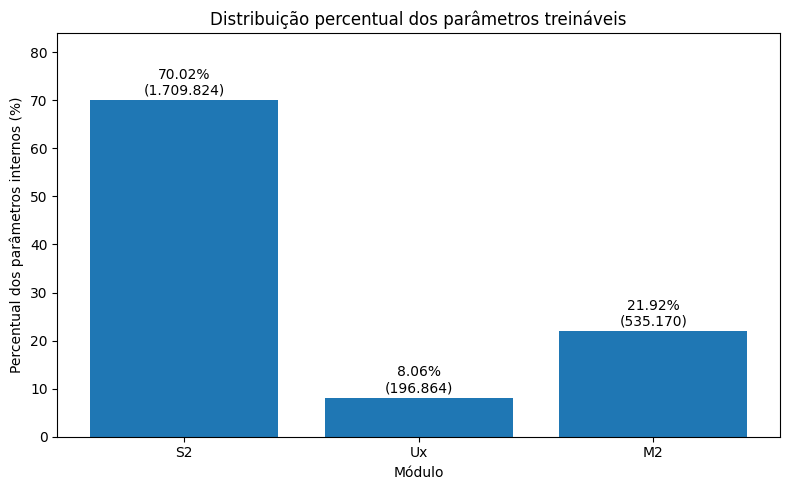

In [10]:
import matplotlib.pyplot as plt

# Considerar somente os módulos internos
modulos = ["S2", "Ux", "M2"]
parametros = [1_709_824, 196_864, 535_170]

total_interno = sum(parametros)
percentuais = [
    (quantidade / total_interno) * 100
    for quantidade in parametros
]

plt.figure(figsize=(8, 5))

barras = plt.bar(modulos, percentuais)

plt.title("Distribuição percentual dos parâmetros treináveis")
plt.xlabel("Módulo")
plt.ylabel("Percentual dos parâmetros internos (%)")
plt.ylim(0, max(percentuais) * 1.2)

for barra, percentual, quantidade in zip(
    barras, percentuais, parametros
):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.5,
        f"{percentual:.2f}%\n({quantidade:,})".replace(",", "."),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

Quantidade de parâmetros analisados:


Tipo,Peso,Viés
Módulo,,
M2,532032,3138
S2,1705472,4352


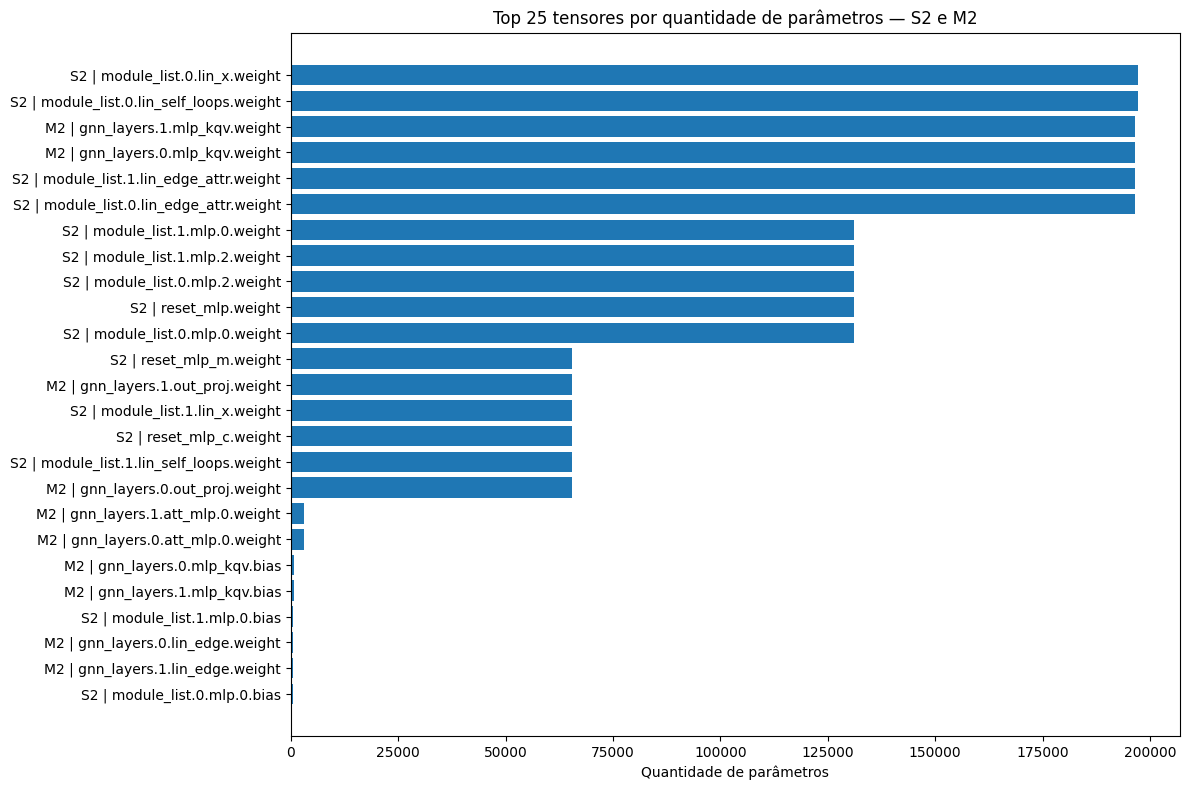

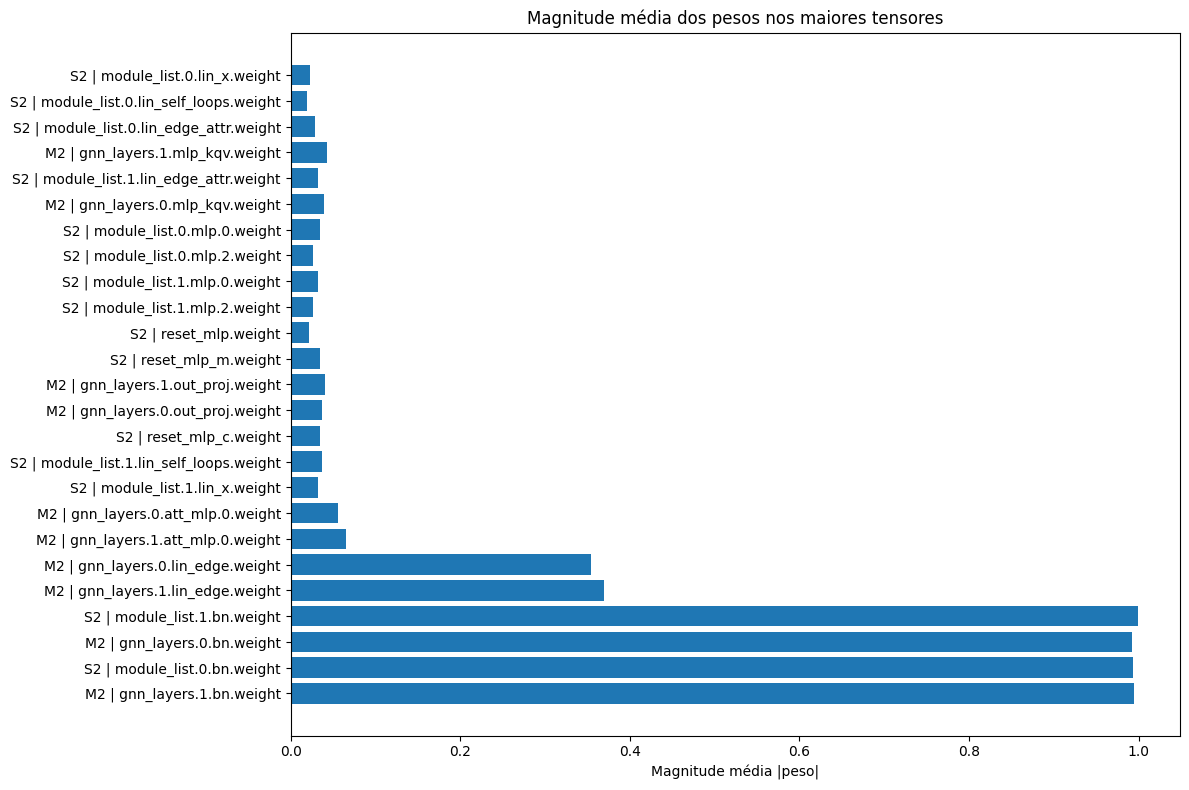

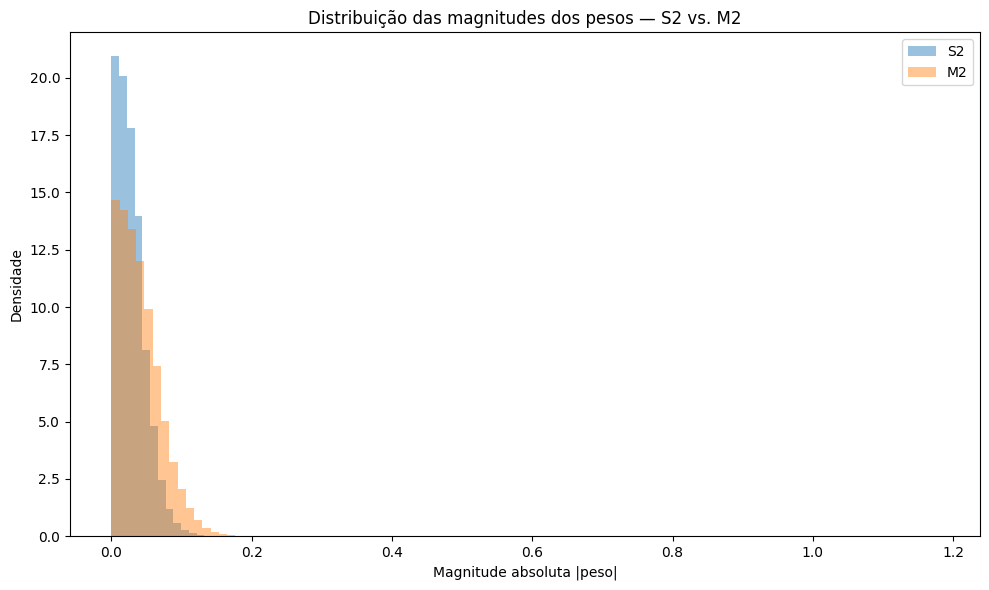

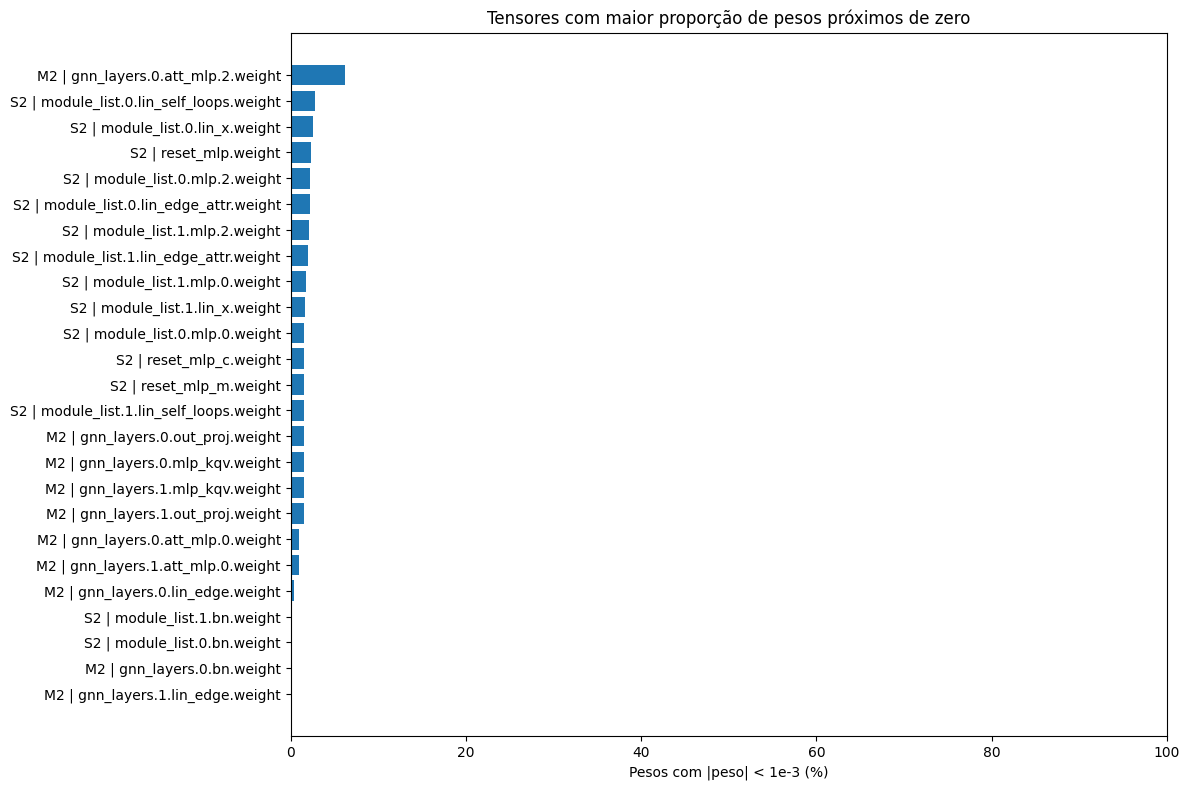

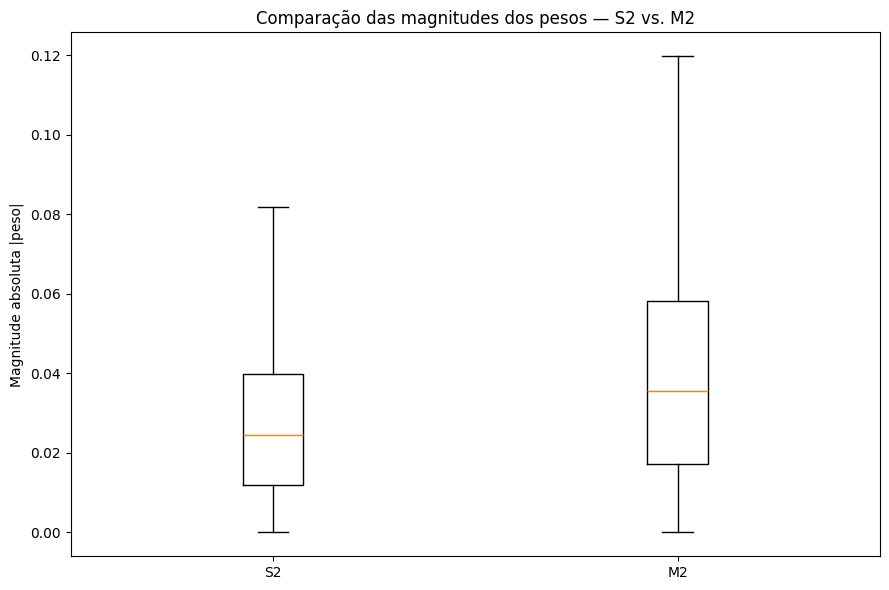

,Módulo,Tensor,Tipo,Formato,Parâmetros,Treináveis,Magnitude média,Magnitude mediana,Magnitude máxima,% abaixo de 1e-3,% abaixo de 1e-2,% abaixo de 1e-1
30,M2,gnn_layers.0.mlp_kqv.weight,Peso,"(768, 256)","196,608",True,0.039203,0.034478,0.220355,1.51%,14.99%,96.51%
42,M2,gnn_layers.1.mlp_kqv.weight,Peso,"(768, 256)","196,608",True,0.042241,0.036743,0.231729,1.50%,14.33%,94.76%
38,M2,gnn_layers.0.out_proj.weight,Peso,"(256, 256)","65,536",True,0.037468,0.033304,0.216377,1.55%,15.52%,97.77%
50,M2,gnn_layers.1.out_proj.weight,Peso,"(256, 256)","65,536",True,0.040311,0.035391,0.230390,1.47%,14.60%,96.08%
34,M2,gnn_layers.0.att_mlp.0.weight,Peso,"(32, 96)","3,072",True,0.055697,0.050726,0.209775,0.91%,10.22%,87.30%
46,M2,gnn_layers.1.att_mlp.0.weight,Peso,"(32, 96)","3,072",True,0.065760,0.057370,0.238441,0.91%,9.21%,76.24%
31,M2,gnn_layers.0.mlp_kqv.bias,Viés,"(768,)",768,True,0.039382,0.036148,0.150937,1.69%,12.37%,97.14%
43,M2,gnn_layers.1.mlp_kqv.bias,Viés,"(768,)",768,True,0.037466,0.032867,0.180552,2.21%,16.41%,96.88%
32,M2,gnn_layers.0.lin_edge.weight,Peso,"(256, 2)",512,True,0.354269,0.339260,0.736382,0.39%,2.15%,12.30%
44,M2,gnn_layers.1.lin_edge.weight,Peso,"(256, 2)",512,True,0.369691,0.394529,0.855963,0.00%,0.98%,13.87%


In [29]:

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Selecionar os módulos que serão analisados
# ============================================================

modulos = {
    "S2": model.layer_list[0],
    "M2": model.layer_list[2],
}

# ============================================================
# 2. Coletar estatísticas de cada tensor
# ============================================================

registros = []
distribuicoes = {}

for nome_modulo, modulo in modulos.items():
    for nome, parametro in modulo.named_parameters():

        # Evitar misturar os parâmetros de um módulo com os de outro
        valores = parametro.detach().float().cpu()
        magnitude = valores.abs()

        # "weight" inclui matrizes de pesos e parâmetros de escala
        # de normalização. Biases são analisados separadamente.
        if "weight" in nome:
            tipo = "Peso"
        elif "bias" in nome:
            tipo = "Viés"
        else:
            tipo = "Outro parâmetro"

        registros.append({
            "Módulo": nome_modulo,
            "Tensor": nome,
            "Tipo": tipo,
            "Formato": str(tuple(valores.shape)),
            "Parâmetros": valores.numel(),
            "Treináveis": parametro.requires_grad,
            "Média": valores.mean().item(),
            "Desvio padrão": valores.std(unbiased=False).item(),
            "Magnitude média": magnitude.mean().item(),
            "Magnitude mediana": magnitude.median().item(),
            "Magnitude máxima": magnitude.max().item(),
            "% abaixo de 1e-3": (magnitude < 1e-3).float().mean().item() * 100,
            "% abaixo de 1e-2": (magnitude < 1e-2).float().mean().item() * 100,
            "% abaixo de 1e-1": (magnitude < 1e-1).float().mean().item() * 100,
        })

        # Para estudar magnitude pruning, guardamos separadamente
        # os valores dos tensores identificados como pesos.
        if tipo == "Peso":
            distribuicoes[(nome_modulo, nome)] = magnitude.flatten().numpy()

df = pd.DataFrame(registros)

print("Quantidade de parâmetros analisados:")
display(
    df.groupby(["Módulo", "Tipo"])["Parâmetros"]
      .sum()
      .unstack(fill_value=0)
)

# ============================================================
# GRÁFICO 1 — Quantidade de parâmetros por tensor
# ============================================================

top = df.sort_values("Parâmetros", ascending=False).head(25).copy()
top["Identificação"] = top["Módulo"] + " | " + top["Tensor"]

plt.figure(figsize=(12, 8))
plt.barh(top["Identificação"][::-1], top["Parâmetros"][::-1])
plt.xlabel("Quantidade de parâmetros")
plt.title("Top 25 tensores por quantidade de parâmetros — S2 e M2")
plt.tight_layout()
plt.show()

# ============================================================
# GRÁFICO 2 — Magnitude média dos pesos por tensor
# ============================================================

pesos_df = df[df["Tipo"] == "Peso"].copy()
top_mag = pesos_df.sort_values("Parâmetros", ascending=False).head(25).copy()
top_mag["Identificação"] = top_mag["Módulo"] + " | " + top_mag["Tensor"]

plt.figure(figsize=(12, 8))
plt.barh(
    top_mag["Identificação"][::-1],
    top_mag["Magnitude média"][::-1]
)
plt.xlabel("Magnitude média |peso|")
plt.title("Magnitude média dos pesos nos maiores tensores")
plt.tight_layout()
plt.show()

# ============================================================
# GRÁFICO 3 — Distribuição das magnitudes dos pesos
# ============================================================

plt.figure(figsize=(10, 6))

for nome_modulo in modulos:
    arrays = [
        valores
        for (modulo_nome, _), valores in distribuicoes.items()
        if modulo_nome == nome_modulo
    ]

    if arrays:
        valores = np.concatenate(arrays)
        plt.hist(
            valores,
            bins=100,
            density=True,
            alpha=0.45,
            label=nome_modulo
        )

plt.xlabel("Magnitude absoluta |peso|")
plt.ylabel("Densidade")
plt.title("Distribuição das magnitudes dos pesos — S2 vs. M2")
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# GRÁFICO 4 — Percentual de pesos próximos de zero por tensor
# ============================================================

top_zero = pesos_df.sort_values("% abaixo de 1e-3", ascending=False).head(25).copy()
top_zero["Identificação"] = top_zero["Módulo"] + " | " + top_zero["Tensor"]

plt.figure(figsize=(12, 8))
plt.barh(
    top_zero["Identificação"][::-1],
    top_zero["% abaixo de 1e-3"][::-1]
)
plt.xlabel("Pesos com |peso| < 1e-3 (%)")
plt.title("Tensores com maior proporção de pesos próximos de zero")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

# ============================================================
# GRÁFICO 5 — Comparação de magnitudes por módulo
# ============================================================

plt.figure(figsize=(9, 6))

dados_boxplot = [
    np.concatenate([
        valores
        for (modulo_nome, _), valores in distribuicoes.items()
        if modulo_nome == nome_modulo
    ])
    for nome_modulo in modulos
]

plt.boxplot(
    dados_boxplot,
    tick_labels=list(modulos.keys()),
    showfliers=False
)
plt.ylabel("Magnitude absoluta |peso|")
plt.title("Comparação das magnitudes dos pesos — S2 vs. M2")
plt.tight_layout()
plt.show()

# ============================================================
# TABELA DETALHADA
# ============================================================

colunas = [
    "Módulo", "Tensor", "Tipo", "Formato", "Parâmetros",
    "Treináveis", "Magnitude média", "Magnitude mediana",
    "Magnitude máxima", "% abaixo de 1e-3",
    "% abaixo de 1e-2", "% abaixo de 1e-1"
]

display(
    df[colunas]
    .sort_values(["Módulo", "Parâmetros"], ascending=[True, False])
    .style.format({
        "Parâmetros": "{:,.0f}",
        "Magnitude média": "{:.6f}",
        "Magnitude mediana": "{:.6f}",
        "Magnitude máxima": "{:.6f}",
        "% abaixo de 1e-3": "{:.2f}%",
        "% abaixo de 1e-2": "{:.2f}%",
        "% abaixo de 1e-1": "{:.2f}%",
    })
)


Analise de influencia modular e camadas

In [6]:
%cd C:\Mestrado\Graph_Pruning\prodigy

C:\Mestrado\Graph_Pruning\prodigy


In [42]:

from pathlib import Path
import sys
import gc

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# Caminhos do projeto
PROJECT_ROOT = Path(r"C:\Mestrado\Graph_Pruning")
REPO_ROOT = PROJECT_ROOT / "prodigy"
DATA_ROOT = REPO_ROOT / "data" / "datasets"

CHECKPOINT_DIR = (
    REPO_ROOT / "state" / "exp1_16_10_2026_15_33_55"
)

# Permitir imports do PRODIGY
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Dispositivo
device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

print("Repositório:", REPO_ROOT)
print("Dataset:", DATA_ROOT / "FB15K-237")
print("Checkpoint:", CHECKPOINT_DIR)
print("Dispositivo:", device)
print("CUDA disponível:", torch.cuda.is_available())


Repositório: C:\Mestrado\Graph_Pruning\prodigy
Dataset: C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237
Checkpoint: C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_15_33_55
Dispositivo: cuda:0
CUDA disponível: True


In [43]:

CONFIG = {
    "dataset": "FB15K-237",
    "layers": "S2,UX,M2",
    "task_name": "cls_nm",
    "n_way": 3,
    "n_shot": 3,
    "n_query": 3,
    "batch_size": 1,
    "dataset_len_cap": 510,
    "val_len_cap": 100,
    "test_len_cap": 500,
    "train_cap": 10,
    "num_workers": 0,
    "emb_dim": 256,
    "input_dim": 770,
}

print(pd.Series(CONFIG, name="Valor"))


dataset            FB15K-237
layers              S2,UX,M2
task_name             cls_nm
n_way                      3
n_shot                     3
n_query                    3
batch_size                 1
dataset_len_cap          510
val_len_cap              100
test_len_cap             500
train_cap                 10
num_workers                0
emb_dim                  256
input_dim                770
Name: Valor, dtype: object


In [44]:
import torch

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("Dispositivo:", DEVICE)

Dispositivo: cuda:0


In [45]:
from data.data_loader_wrapper import get_dataset_wrap

datasets = get_dataset_wrap(
    root=str(DATA_ROOT),
    dataset=CONFIG["dataset"],
    n_hop=1,
    bert="sentence-transformers/all-mpnet-base-v2",
    bert_device=str(DEVICE),
    node_graph=False,
)

print("Dataset carregado:", type(datasets).__name__)
print("Dataset:", CONFIG["dataset"])

Use cache from:  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\relation2id.json
Use cache from:  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\entity2id.json


100%|██████████| 200/200 [00:00<00:00, 2667.20it/s]


Use cache from:  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\graph.pt
Use cache from:  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\graph.pt
MODEL NAME:  sentence-transformers/all-mpnet-base-v2
Loading text features from  C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\preproc_text_feats\text_feats_sentence-transformers_all-mpnet-base-v2_.pkl
Loading adjacent matrix for neighbor sampling from C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\FB15K-237_adj.pt
Loaded adjacent matrix for neighbor sampling from C:\Mestrado\Graph_Pruning\prodigy\data\datasets\FB15K-237\FB15K-237_adj.pt
Dataset carregado: KGSubgraphDataset
Dataset: FB15K-237


In [46]:

from data.kg import get_kg_dataloader

dataset_name = CONFIG["dataset"]

dataset_root = str(DATA_ROOT / dataset_name)

loader_kwargs = {
    "batch_size": CONFIG["batch_size"],
    "n_way": CONFIG["n_way"],
    "n_shot": CONFIG["n_shot"],
    "n_query": CONFIG["n_query"],
    "root": dataset_root,
    "num_workers": CONFIG["num_workers"],
    "aug": None,
    "aug_test": None,
    "train_cap": CONFIG["train_cap"],
    "linear_probe": False,
    "split_labels": True,
    "csr_split": False,
}

val_loader = get_kg_dataloader(
    datasets,
    task_name=CONFIG["task_name"],
    split="val",
    node_split="",
    batch_count=CONFIG["val_len_cap"],
    **loader_kwargs,
)

test_loader = get_kg_dataloader(
    datasets,
    task_name=CONFIG["task_name"],
    split="test",
    node_split="",
    batch_count=CONFIG["test_len_cap"],
    **loader_kwargs,
)

print("Lotes de validação:", len(val_loader))
print("Lotes de teste:", len(test_loader))


200
TEST_LABELS 120
VAL_LABELS 40
TRAIN_LABELS 40
200
TEST_LABELS 120
VAL_LABELS 40
TRAIN_LABELS 40
Lotes de validação: 100
Lotes de teste: 500


In [47]:
import sys
from experiments.params import get_params

argv_original = sys.argv.copy()

try:
    sys.argv = [
        "notebook",
        "-root", str(DATA_ROOT),
        "-dataset", "FB15K-237",
        "-layers", "S2,UX,M2",
        "-task", "cls_nm",
        "-way", "3",
        "-shot", "3",
        "-qry", "3",
        "-bs", "1",
        "-ds_cap", "510",
        "-val_cap", "100",
        "-test_cap", "500",
        "-eval_step", "100",
        "-epochs", "3",
        "-train_cap", "10",
        "-gpu", "0",
        "-workers", "0",
    ]

    params = get_params()

finally:
    sys.argv = argv_original
params["input_dim"] = 770
params["bert_emb_model"] = "sentence-transformers/all-mpnet-base-v2"

print("Dataset:", params["dataset"])
print("Camadas:", params["layers"])
print("Tarefa:", params["task_name"])
print("Dispositivo:", params["device"])
print("Dimensão dos embeddings:", params["emb_dim"])
print("Dimensão de entrada:", params["input_dim"])
print("Dimensão dos embeddings:", params["emb_dim"])
print("Dimensão de entrada:", params["input_dim"])
print("Parâmetros preparados:", len(params))

Dataset: FB15K-237
Camadas: S2,UX,M2
Tarefa: cls_nm
Dispositivo: cuda:0
Dimensão dos embeddings: 256
Dimensão de entrada: 770
Dimensão dos embeddings: 256
Dimensão de entrada: 770
Parâmetros preparados: 80


In [54]:
import torch
from pathlib import Path

from models.general_gnn import SingleLayerGeneralGNN
from experiments.layers import get_module_list

# Reproduzir a configuração original do FB15K-237
bert_dim = 768
params["input_dim"] = bert_dim + 2
params["emb_dim"] = 256

initial_label_mlp = torch.nn.Linear(bert_dim, params["emb_dim"])
text_dropout = torch.nn.Dropout(params["text_features_dropout"])

layer_list = get_module_list(
    module_string=params["layers"],
    emb_dim=params["emb_dim"],
    edge_attr_dim=bert_dim,
    input_dim=params["input_dim"],
    dropout=params["dropout"],
    reset_after_layer=params["reset_after_layer"],
    attention_mask_scheme=params["attention_mask_scheme"],
    has_final_back=params["has_final_back"],
    msg_pos_only=params.get("meta_gnn_pos_only", False),
    batch_norm_metagraph=not params["no_bn_metagraph"],
    batch_norm_encoder=not params["no_bn_encoder"],
    gnn_use_relu=True,
)

model = SingleLayerGeneralGNN(
    layer_list=torch.nn.ModuleList(layer_list),
    initial_label_mlp=initial_label_mlp,
    params=params,
    text_dropout=text_dropout,
).to(DEVICE)

model.eval()

print("Modelo construído:", type(model).__name__)
print("Camadas:", [type(layer).__name__ for layer in model.layer_list])
print("Dispositivo:", next(model.parameters()).device)
print("Parâmetros totais:", sum(p.numel() for p in model.parameters()))


Modelo construído: SingleLayerGeneralGNN
Camadas: ['MultiLayerGNN', 'BgGraphToSupernodePropagatorCat', 'MetaGNN']
Dispositivo: cuda:0
Parâmetros totais: 2894723


In [55]:
# Carregar o checkpoint treinado

checkpoint_path = CHECKPOINT_DIR / "state_dict"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

state_dict = checkpoint["model"]

# Carregar os pesos, exigindo compatibilidade completa
model.load_state_dict(state_dict, strict=True)

# Preparar o modelo para inferência
model = model.to(DEVICE)
model.eval()

print("Checkpoint carregado com sucesso!")
print("Modo de avaliação:", not model.training)
print("Dispositivo:", next(model.parameters()).device)
print("Parâmetros totais:", sum(p.numel() for p in model.parameters()))

Checkpoint carregado com sucesso!
Modo de avaliação: True
Dispositivo: cuda:0
Parâmetros totais: 2894723


In [56]:

print("Parâmetros do modelo:")
print(model.params)

print("\nBlocos:")
for i, layer in enumerate(model.layer_list):
    print(f"layer_list[{i}]: {type(layer).__name__}")

assert not model.training


Parâmetros do modelo:
{'root': 'C:\\Mestrado\\Graph_Pruning\\prodigy\\data\\datasets', 'dataset': 'FB15K-237', 'invalidate_cache': False, 'dataset_len_cap': 510, 'val_len_cap': 100, 'test_len_cap': 500, 'shuffle_index': False, 'force_cache': False, 'classification_only': False, 'early_stopping_patience': 20, 'reset_after_layer': None, 'original_features': False, 'override_log': False, 'seed': None, 'metric': 'Acc', 'learning_rate': 0.001, 'epochs': 3, 'print_epoch': 10, 'eval_epoch': 10, 'checkpoint_epoch': 10, 'print_step': 2000, 'eval_step': 100, 'checkpoint_step': 2000, 'batch_size': 1, 'weight_decay': 0.001, 'dropout': 0, 'text_features_dropout': 0, 'rel_sample_random_seed': None, 'split_train_nodes': False, 'verbose': False, 'workers': 0, 'device': device(type='cuda', index=0), 'input_dim': 770, 'emb_dim': 256, 'gnn_type': 'sage', 'n_layer': 1, 'meta_n_layer': 1, 'second_gnn': 'Atten', 'attention_mask_scheme': 'causal', 'skip_path': False, 'has_final_back': False, 'layers': 'S2,UX

In [57]:

batch = next(iter(val_loader))

batch = [
    item.to(device) if hasattr(item, "to") else item
    for item in batch
]

with torch.no_grad():
    output = model(
        batch[0],
        batch[1],
        batch[2],
        batch[3],
        batch[4],
        batch[5],
        batch[6],
        batch[7],
        batch[8],
    )

print("Número de saídas:", len(output))
print("Shape de y_true:", output[0].shape)
print("Shape de y_pred:", output[1].shape)
print("Modo avaliação:", not model.training)


Número de saídas: 3
Shape de y_true: torch.Size([9, 3])
Shape de y_pred: torch.Size([9, 3])
Modo avaliação: True


In [58]:

s2 = model.layer_list[0]
m2 = model.layer_list[2]

captured = {
    "S2": {},
    "M2": {}
}

# Guardar os métodos originais para restaurá-los depois
original_s2_forward = s2.forward
original_m2_forward = m2.forward


# Captura a saída final de S2
def s2_capture_forward(*args, **kwargs):
    output = original_s2_forward(*args, **kwargs)

    # Guardar na CPU para reduzir o uso de memória GPU
    captured["S2"]["output"] = output.detach().cpu()

    return output


# Captura entrada e saída de M2
def m2_capture_forward(*args, **kwargs):
    x_in = kwargs.get("x", args[0] if args else None)
    n_supernodes = kwargs.get("start_right")

    output = original_m2_forward(*args, **kwargs)

    captured["M2"]["input"] = x_in.detach().cpu()
    captured["M2"]["output"] = output.detach().cpu()
    captured["M2"]["n_supernodes"] = n_supernodes

    return output


# A primeira camada GraphSAGE é chamada como módulo PyTorch.
# Seu hook captura a saída projetada para 256 dimensões.
def s2_first_layer_hook(module, args, kwargs, output):
    if not torch.is_tensor(output):
        raise TypeError(
            "A saída da primeira camada S2 não é um tensor."
        )

    captured["S2"]["first_layer"] = output.detach().cpu()


first_s2_layer = s2.module_list[0]

first_layer_handle = first_s2_layer.register_forward_hook(
    s2_first_layer_hook,
    with_kwargs=True
)

s2.forward = s2_capture_forward
m2.forward = m2_capture_forward

print("Captura preparada.")


Captura preparada.


In [59]:

captured["S2"].clear()
captured["M2"].clear()

batch = next(iter(val_loader))
batch = [
    item.to(device) if hasattr(item, "to") else item
    for item in batch
]

try:
    with torch.no_grad():
        model(
            batch[0], batch[1], batch[2], batch[3], batch[4],
            batch[5], batch[6], batch[7], batch[8]
        )

    print(
        "S2 primeira camada:",
        captured["S2"]["first_layer"].shape
    )
    print(
        "S2 saída final:",
        captured["S2"]["output"].shape
    )
    print(
        "M2 entrada:",
        captured["M2"]["input"].shape
    )
    print(
        "M2 saída:",
        captured["M2"]["output"].shape
    )

finally:
    # Restaurar a arquitetura original
    s2.forward = original_s2_forward
    m2.forward = original_m2_forward
    first_layer_handle.remove()


S2 primeira camada: torch.Size([1571, 256])
S2 saída final: torch.Size([1571, 256])
M2 entrada: torch.Size([21, 256])
M2 saída: torch.Size([21, 256])


In [60]:

def cosine_distances(x_in, x_out, eps=1e-8):
    x_in = x_in.reshape(-1, x_in.shape[-1]).float()
    x_out = x_out.reshape(-1, x_out.shape[-1]).float()

    if x_in.shape != x_out.shape:
        raise ValueError(
            f"Dimensões incompatíveis: "
            f"{tuple(x_in.shape)} vs {tuple(x_out.shape)}"
        )

    norm_in = torch.linalg.vector_norm(x_in, dim=1)
    norm_out = torch.linalg.vector_norm(x_out, dim=1)

    valid = (norm_in > eps) & (norm_out > eps)

    if not valid.any():
        return torch.empty(0)

    return 1 - F.cosine_similarity(
        x_in[valid],
        x_out[valid],
        dim=1,
        eps=eps
    )


Modular

In [61]:

bi_by_batch = {
    "S2": [],
    "M2": []
}

valid_nodes = {
    "S2": 0,
    "M2": 0
}

s2 = model.layer_list[0]
m2 = model.layer_list[2]

original_s2_forward = s2.forward
original_m2_forward = m2.forward
first_s2_layer = s2.module_list[0]

captured = {
    "S2": {},
    "M2": {}
}


def s2_capture_forward(*args, **kwargs):
    output = original_s2_forward(*args, **kwargs)
    captured["S2"]["output"] = output.detach().cpu()
    return output


def m2_capture_forward(*args, **kwargs):
    x_in = kwargs.get("x", args[0] if args else None)
    n_supernodes = kwargs.get("start_right")

    output = original_m2_forward(*args, **kwargs)

    captured["M2"]["input"] = x_in.detach().cpu()
    captured["M2"]["output"] = output.detach().cpu()
    captured["M2"]["n_supernodes"] = n_supernodes

    return output


def s2_first_layer_hook(module, args, kwargs, output):
    captured["S2"]["first_layer"] = output.detach().cpu()


handle = first_s2_layer.register_forward_hook(
    s2_first_layer_hook,
    with_kwargs=True
)

s2.forward = s2_capture_forward
m2.forward = m2_capture_forward

model.eval()

try:
    with torch.no_grad():
        for i, batch in enumerate(val_loader):
            captured["S2"].clear()
            captured["M2"].clear()

            batch = [
                item.to(device) if hasattr(item, "to") else item
                for item in batch
            ]

            model(
                batch[0], batch[1], batch[2], batch[3], batch[4],
                batch[5], batch[6], batch[7], batch[8]
            )

            # BI do S2:
            # primeira camada GraphSAGE após ReLU -> saída final do bloco
            s2_intermediate = F.relu(
                captured["S2"]["first_layer"]
            )
            s2_output = captured["S2"]["output"]

            s2_dist = cosine_distances(
                s2_intermediate,
                s2_output
            )

            if s2_dist.numel():
                bi_by_batch["S2"].append(s2_dist.mean().item())
                valid_nodes["S2"] += s2_dist.numel()

            # BI do M2: apenas os supernós
            m2_input = captured["M2"]["input"]
            m2_output = captured["M2"]["output"]
            n_supernodes = captured["M2"]["n_supernodes"]

            m2_dist = cosine_distances(
                m2_input[:n_supernodes],
                m2_output[:n_supernodes]
            )

            if m2_dist.numel():
                bi_by_batch["M2"].append(m2_dist.mean().item())
                valid_nodes["M2"] += m2_dist.numel()

            if (i + 1) % 10 == 0:
                print(
                    f"Lotes processados: {i + 1}/{len(val_loader)}"
                )

finally:
    s2.forward = original_s2_forward
    m2.forward = original_m2_forward
    handle.remove()

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("Avaliação concluída.")


Lotes processados: 10/100
Lotes processados: 20/100
Lotes processados: 30/100
Lotes processados: 40/100
Lotes processados: 50/100
Lotes processados: 60/100
Lotes processados: 70/100
Lotes processados: 80/100
Lotes processados: 90/100
Lotes processados: 100/100
Avaliação concluída.


In [62]:

rows = []

for block in ("S2", "M2"):
    values = np.asarray(bi_by_batch[block], dtype=float)

    if len(values) == 0:
        print(f"Sem resultados válidos para {block}.")
        continue

    rows.append({
        "Bloco": block,
        "BI médio entre lotes": values.mean(),
        "Desvio padrão entre lotes": values.std(ddof=0),
        "Lotes válidos": len(values),
        "Nós válidos": valid_nodes[block]
    })

bi_results = pd.DataFrame(rows)

display(bi_results.round(6))

output_path = CHECKPOINT_DIR / "bi_validation_s2_m2.csv"
bi_results.to_csv(output_path, index=False)

print("Resultados salvos em:", output_path)


,Bloco,BI médio entre lotes,Desvio padrão entre lotes,Lotes válidos,Nós válidos
0,S2,0.237383,0.007999,100,168130
1,M2,0.837076,0.112997,100,1800


Resultados salvos em: C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_15_33_55\bi_validation_s2_m2.csv


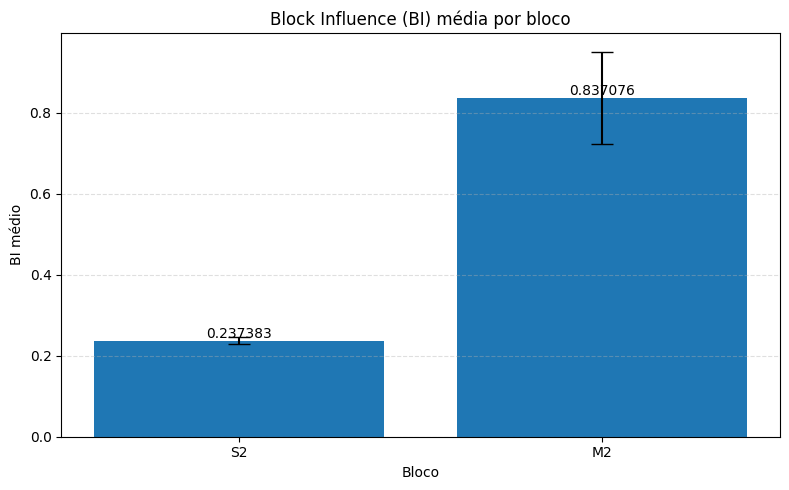

In [64]:
import matplotlib.pyplot as plt
import numpy as np

df = bi_results.copy()

plt.figure(figsize=(8, 5))

barras = plt.bar(
    df["Bloco"],
    df["BI médio entre lotes"],
    yerr=df["Desvio padrão entre lotes"],
    capsize=8
)

plt.title("Block Influence (BI) média por bloco")
plt.xlabel("Bloco")
plt.ylabel("BI médio")
plt.grid(axis="y", linestyle="--", alpha=0.4)

for barra, valor in zip(barras, df["BI médio entre lotes"]):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"{valor:.6f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / "bi_media_por_bloco.png", dpi=300)
plt.show()

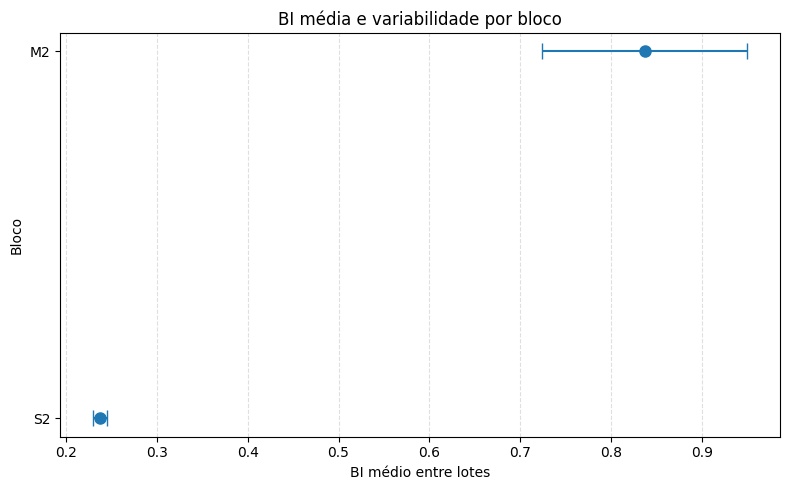

In [65]:
plt.figure(figsize=(8, 5))

plt.errorbar(
    df["BI médio entre lotes"],
    df["Bloco"],
    xerr=df["Desvio padrão entre lotes"],
    fmt="o",
    capsize=6,
    markersize=8
)

plt.title("BI média e variabilidade por bloco")
plt.xlabel("BI médio entre lotes")
plt.ylabel("Bloco")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / "bi_variabilidade_por_bloco.png", dpi=300)
plt.show()

Camadas

In [68]:
import inspect
import gc
import numpy as np
import pandas as pd
import torch

# Blocos e camadas internas
s2 = model.layer_list[0]
m2 = model.layer_list[2]

s2_layers = list(s2.module_list)
m2_layers = list(m2.gnn_layers)

# Guardar os forwards originais
original_s2_forward = s2.forward
original_m2_forward = m2.forward
m2_signature = inspect.signature(original_m2_forward)

# Armazenar somente as ativações necessárias
captured_layers = {
    "S2": {},
    "M2": {}
}

# Saída final de cada bloco e número de supernós
captured_outputs = {
    "S2": None,
    "M2": None
}
n_supernodes_captured = {"value": None}


def collect_tensors(obj):
    """Obtém os tensores contidos em argumentos, tuplas, listas ou dicionários."""
    if torch.is_tensor(obj):
        return [obj]

    if isinstance(obj, (tuple, list)):
        tensors = []
        for item in obj:
            tensors.extend(collect_tensors(item))
        return tensors

    if isinstance(obj, dict):
        tensors = []
        for item in obj.values():
            tensors.extend(collect_tensors(item))
        return tensors

    return []


def first_matrix(obj):
    """Obtém o primeiro tensor com pelo menos duas dimensões."""
    return next(
        (t for t in collect_tensors(obj) if t.ndim >= 2),
        None
    )


def make_layer_hook(block_name, layer_idx):
    def hook(module, args, kwargs, output):
        out_tensor = first_matrix(output)

        if out_tensor is None:
            captured_layers[block_name][layer_idx] = None
            return

        inputs = [
            t for t in collect_tensors((args, kwargs))
            if t.ndim >= 2
        ]

        # Preferir a representação com a mesma forma da saída.
        matches = [
            t for t in inputs
            if tuple(t.shape) == tuple(out_tensor.shape)
        ]

        # Alternativa para implementações que alteram a dimensão
        # do primeiro eixo, mas preservam o embedding.
        if not matches:
            matches = [
                t for t in inputs
                if t.ndim == out_tensor.ndim
                and t.shape[-1] == out_tensor.shape[-1]
            ]

        if not matches:
            captured_layers[block_name][layer_idx] = None
            return

        captured_layers[block_name][layer_idx] = (
            matches[0].detach().cpu()
        )

    return hook


def s2_capture_forward(*args, **kwargs):
    output = original_s2_forward(*args, **kwargs)
    output_tensor = first_matrix(output)

    captured_outputs["S2"] = (
        output_tensor.detach().cpu()
        if output_tensor is not None else None
    )

    return output


def m2_capture_forward(*args, **kwargs):
    # Recuperar start_right mesmo se tiver sido passado
    # como argumento posicional.
    try:
        bound = m2_signature.bind_partial(*args, **kwargs)
        n_supernodes = bound.arguments.get("start_right")
    except TypeError:
        n_supernodes = kwargs.get("start_right")

    if n_supernodes is not None:
        if torch.is_tensor(n_supernodes):
            n_supernodes = n_supernodes.item()

        n_supernodes_captured["value"] = int(n_supernodes)

    output = original_m2_forward(*args, **kwargs)
    output_tensor = first_matrix(output)

    captured_outputs["M2"] = (
        output_tensor.detach().cpu()
        if output_tensor is not None else None
    )

    return output


# Registrar hooks em todas as camadas internas
handles = []

for i, layer in enumerate(s2_layers):
    handles.append(
        layer.register_forward_hook(
            make_layer_hook("S2", i),
            with_kwargs=True
        )
    )

for i, layer in enumerate(m2_layers):
    handles.append(
        layer.register_forward_hook(
            make_layer_hook("M2", i),
            with_kwargs=True
        )
    )

# Inicializar os resultados
layer_bi_by_batch = {
    ("S2", i): [] for i in range(len(s2_layers))
}
layer_bi_by_batch.update({
    ("M2", i): [] for i in range(len(m2_layers))
})

valid_nodes_by_layer = {
    key: 0 for key in layer_bi_by_batch
}

skipped_by_layer = {
    key: 0 for key in layer_bi_by_batch
}

# Capturar as representações durante a inferência
s2.forward = s2_capture_forward
m2.forward = m2_capture_forward
model.eval()

try:
    with torch.no_grad():
        for batch_idx, batch in enumerate(val_loader):
            captured_layers["S2"].clear()
            captured_layers["M2"].clear()

            captured_outputs["S2"] = None
            captured_outputs["M2"] = None
            n_supernodes_captured["value"] = None

            batch = [
                item.to(device) if hasattr(item, "to") else item
                for item in batch
            ]

            model(
                batch[0], batch[1], batch[2],
                batch[3], batch[4], batch[5],
                batch[6], batch[7], batch[8]
            )

            # Calcular BI de cada camada
            for block_name, layers in [
                ("S2", s2_layers),
                ("M2", m2_layers)
            ]:
                n_layers = len(layers)
                block_output = captured_outputs[block_name]

                for layer_idx in range(n_layers):
                    key = (block_name, layer_idx)

                    h_in = captured_layers[block_name].get(layer_idx)

                    # A saída efetiva de uma camada intermediária
                    # é a entrada recebida pela camada seguinte.
                    if layer_idx + 1 < n_layers:
                        h_out = captured_layers[block_name].get(
                            layer_idx + 1
                        )
                    else:
                        # Para a última camada, usar a saída do bloco,
                        # mantendo a definição do cálculo anterior.
                        h_out = block_output

                    if h_in is None or h_out is None:
                        skipped_by_layer[key] += 1
                        continue

                    # Manter somente os supernós no M2.
                    if block_name == "M2":
                        n_supernodes = n_supernodes_captured["value"]

                        if n_supernodes is None:
                            skipped_by_layer[key] += 1
                            continue

                        h_in = h_in[:n_supernodes]
                        h_out = h_out[:n_supernodes]

                    if h_in.shape != h_out.shape or h_in.shape[0] == 0:
                        skipped_by_layer[key] += 1
                        continue

                    distances = cosine_distances(h_in, h_out).reshape(-1)

                    # Contar somente as observações com BI finita.
                    distances = distances[torch.isfinite(distances)]

                    if distances.numel() == 0:
                        skipped_by_layer[key] += 1
                        continue

                    layer_bi_by_batch[key].append(
                        distances.mean().item()
                    )
                    valid_nodes_by_layer[key] += distances.numel()

            if (batch_idx + 1) % 10 == 0:
                print(
                    f"Lotes processados: "
                    f"{batch_idx + 1}/{len(val_loader)}"
                )

finally:
    s2.forward = original_s2_forward
    m2.forward = original_m2_forward

    for handle in handles:
        handle.remove()

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("Inferência concluída.")

Lotes processados: 10/100
Lotes processados: 20/100
Lotes processados: 30/100
Lotes processados: 40/100
Lotes processados: 50/100
Lotes processados: 60/100
Lotes processados: 70/100
Lotes processados: 80/100
Lotes processados: 90/100
Lotes processados: 100/100
Inferência concluída.


In [69]:
rows = []

for block_name, layers in [
    ("S2", s2_layers),
    ("M2", m2_layers)
]:
    for layer_idx, layer in enumerate(layers):
        key = (block_name, layer_idx)
        values = np.asarray(layer_bi_by_batch[key], dtype=float)

        if len(values) == 0:
            print(
                f"Sem resultados válidos para "
                f"{block_name}, camada {layer_idx + 1}."
            )
            continue

        rows.append({
            "Bloco": block_name,
            "Camada": (
                f"{block_name} - {layer_idx + 1}"
            ),
            "Tipo de camada": type(layer).__name__,
            "BI média": values.mean(),
            "Desvio padrão": values.std(ddof=0),
            "Lotes válidos": len(values),
            "Nós válidos": valid_nodes_by_layer[key],
            "Lotes ignorados": skipped_by_layer[key]
        })

bi_layer_results = pd.DataFrame(rows)

display(bi_layer_results.round(6))

output_path = CHECKPOINT_DIR / "bi_validation_por_camada.csv"
bi_layer_results.to_csv(output_path, index=False)

print("Resultados salvos em:", output_path)

Sem resultados válidos para S2, camada 1.


,Bloco,Camada,Tipo de camada,BI média,Desvio padrão,Lotes válidos,Nós válidos,Lotes ignorados
0,S2,S2 - 2,SAGEConvSelfLoopsV2,0.236744,0.007882,100,165800,0
1,M2,M2 - 1,MetaGNNLayer,0.783794,0.083339,100,1800,0
2,M2,M2 - 2,MetaGNNLayer,0.760372,0.052598,100,1800,0


Resultados salvos em: C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_15_33_55\bi_validation_por_camada.csv


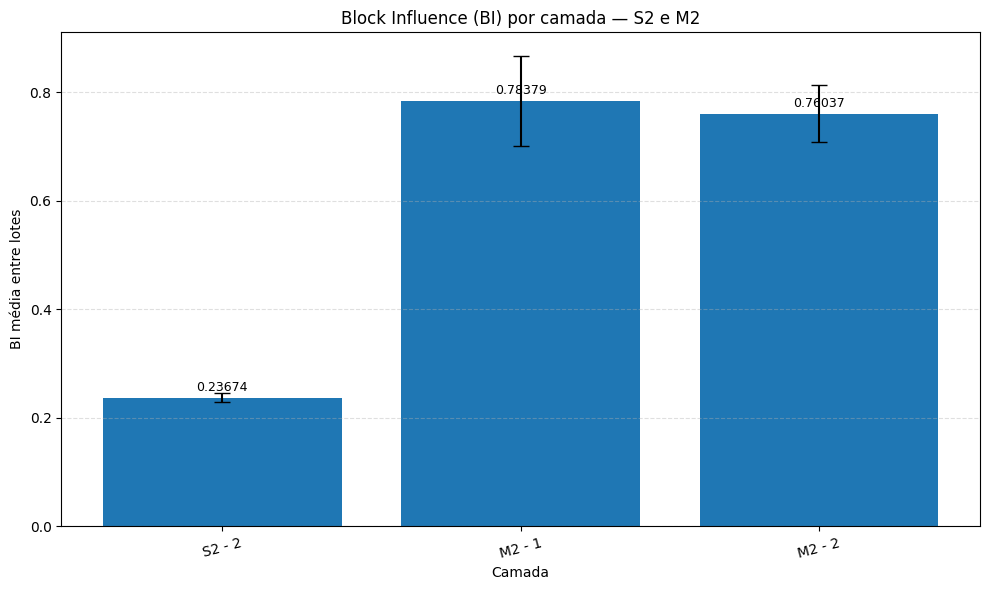

Gráfico salvo em: C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_15_33_55\bi_por_camada_s2_m2.png


In [70]:
import matplotlib.pyplot as plt

if bi_layer_results.empty:
    print("Não há resultados válidos para gerar o gráfico.")
else:
    df_plot = bi_layer_results.copy()

    plt.figure(figsize=(10, 6))

    barras = plt.bar(
        df_plot["Camada"],
        df_plot["BI média"],
        yerr=df_plot["Desvio padrão"],
        capsize=6
    )

    plt.title("Block Influence (BI) por camada — S2 e M2")
    plt.xlabel("Camada")
    plt.ylabel("BI média entre lotes")
    plt.xticks(rotation=15)
    plt.grid(axis="y", linestyle="--", alpha=0.4)

    for barra, valor in zip(barras, df_plot["BI média"]):
        plt.annotate(
            f"{valor:.5f}",
            xy=(
                barra.get_x() + barra.get_width() / 2,
                barra.get_height()
            ),
            xytext=(0, 5 if valor >= 0 else -14),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    plt.tight_layout()

    figura_path = CHECKPOINT_DIR / "bi_por_camada_s2_m2.png"
    plt.savefig(figura_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Gráfico salvo em:", figura_path)

Módulos Linear encontrados: 23
S2.module_list.0.lin_x                   Parâmetros: 197,376
S2.module_list.0.lin_self_loops          Parâmetros: 197,376
S2.module_list.0.lin_edge_attr           Parâmetros: 196,864
S2.module_list.0.mlp.0                   Parâmetros: 131,584
S2.module_list.0.mlp.2                   Parâmetros: 131,328
S2.module_list.1.lin_x                   Parâmetros: 65,792
S2.module_list.1.lin_self_loops          Parâmetros: 65,792
S2.module_list.1.lin_edge_attr           Parâmetros: 196,864
S2.module_list.1.mlp.0                   Parâmetros: 131,584
S2.module_list.1.mlp.2                   Parâmetros: 131,328
S2.reset_mlp                             Parâmetros: 131,328
S2.reset_mlp_c                           Parâmetros: 65,792
S2.reset_mlp_m                           Parâmetros: 65,792
M2.gnn_layers.0.mlp_kqv                  Parâmetros: 197,376
M2.gnn_layers.0.lin_edge                 Parâmetros: 768
M2.gnn_layers.0.att_mlp.0                Parâmetros: 3,104
M2.

,Bloco,Módulo,Parâmetros,BI média por ablação,Desvio padrão,Batches válidos,Predições comparadas,Lotes ignorados,Chamadas ao módulo
0,M2,M2.gnn_layers.0.lin_edge,768,0.000009,0.000017,100,900,0,100
1,S2,S2.module_list.1.lin_edge_attr,196864,0.000951,0.001543,100,900,0,100
2,S2,S2.module_list.0.lin_self_loops,197376,0.001282,0.002469,100,900,0,100
3,S2,S2.module_list.1.lin_x,65792,0.003255,0.004918,100,900,0,100
4,S2,S2.module_list.1.mlp.2,131328,0.007550,0.011008,100,900,0,100
5,S2,S2.module_list.1.mlp.0,131584,0.007567,0.011065,100,900,0,100
6,S2,S2.reset_mlp_m,65792,0.114519,0.153326,100,900,0,100
7,S2,S2.module_list.0.lin_x,197376,0.137338,0.186789,100,900,0,100
8,M2,M2.gnn_layers.1.lin_edge,768,0.145920,0.145359,100,900,0,100
9,S2,S2.reset_mlp_c,65792,0.184558,0.234691,100,900,0,100


Tabela salva em: C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_15_33_55\bi_ablation_modulos_internos.csv


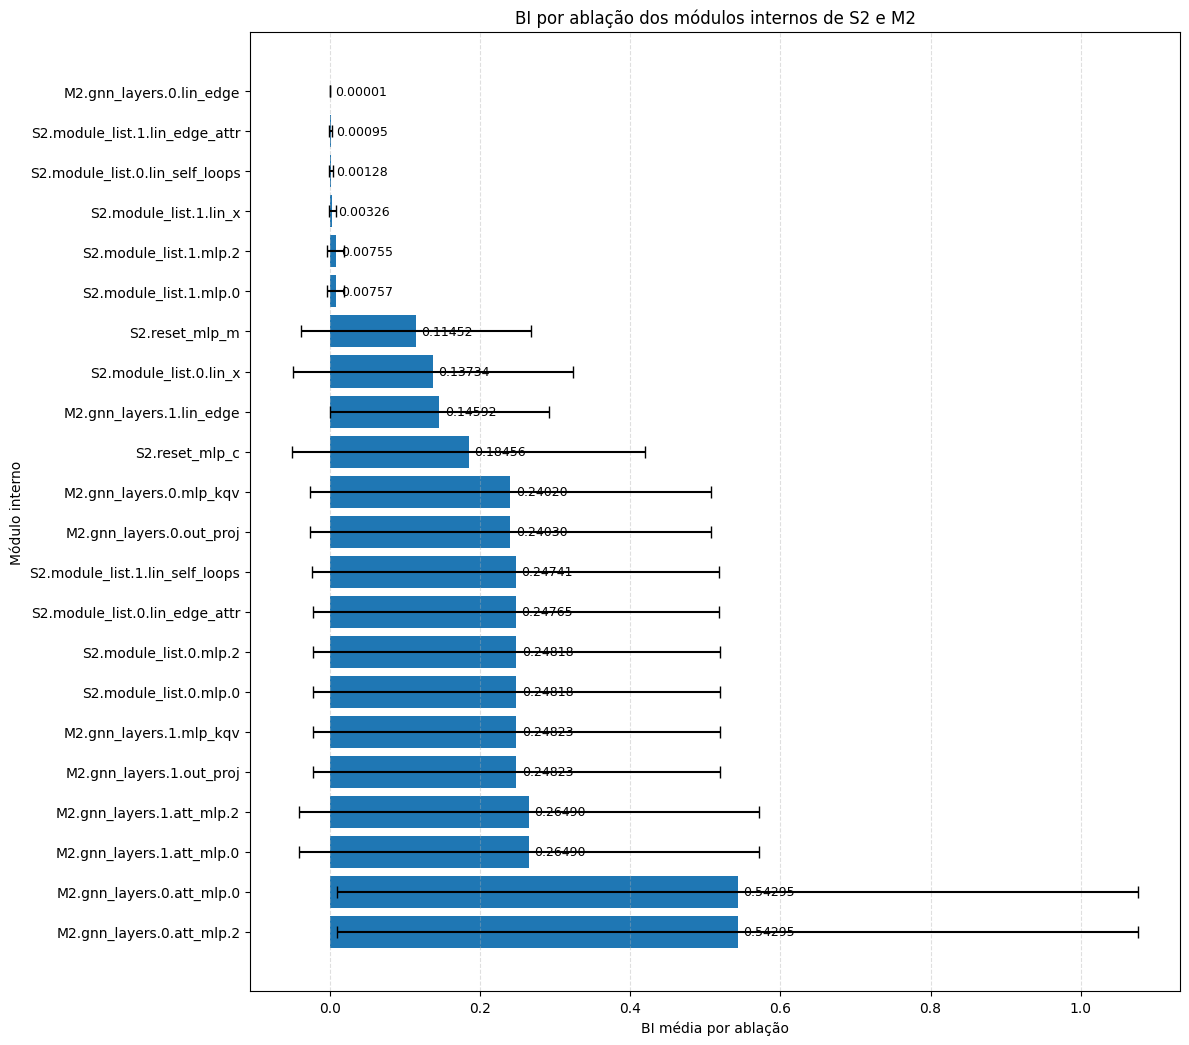

Gráfico salvo em: C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_15_33_55\bi_ablation_modulos_internos.png


In [71]:
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

# ============================================================
# 1. Identificar módulos Linear internos de S2 e M2
# ============================================================

candidates = []

for block_name, block_idx in [("S2", 0), ("M2", 2)]:
    block = model.layer_list[block_idx]

    for module_name, module in block.named_modules():
        if module_name and isinstance(module, nn.Linear):
            n_params = sum(
                p.numel() for p in module.parameters()
            )

            candidates.append({
                "Bloco": block_name,
                "Módulo": f"{block_name}.{module_name}",
                "Camada": module,
                "Parâmetros": n_params
            })

if not candidates:
    raise RuntimeError(
        "Nenhum módulo nn.Linear foi encontrado em S2 e M2."
    )

print(f"Módulos Linear encontrados: {len(candidates)}")

for item in candidates:
    print(
        f'{item["Módulo"]:<40} '
        f'Parâmetros: {item["Parâmetros"]:,}'
    )


# ============================================================
# 2. Guardar os batches para comparar exatamente os mesmos dados
# ============================================================

# None = usar todos os batches do val_loader.
# Para um teste rápido inicial, pode usar MAX_BATCHES = 10.
MAX_BATCHES = None


def clone_cpu(item):
    if torch.is_tensor(item):
        return item.detach().cpu().clone()

    clone_fn = getattr(item, "clone", None)

    if callable(clone_fn):
        cloned = clone_fn()
        cpu_fn = getattr(cloned, "cpu", None)

        if callable(cpu_fn):
            cloned = cpu_fn()

        return cloned

    return item


def fresh_device_batch(batch):
    result = []

    for item in batch:
        if torch.is_tensor(item):
            result.append(item.clone().to(device))
            continue

        clone_fn = getattr(item, "clone", None)

        if callable(clone_fn):
            cloned = clone_fn()
            to_fn = getattr(cloned, "to", None)

            if callable(to_fn):
                cloned = to_fn(device)

            result.append(cloned)
            continue

        to_fn = getattr(item, "to", None)

        if callable(to_fn):
            item = to_fn(device)

        result.append(item)

    return result


cached_batches = []

for i, batch in enumerate(val_loader):
    if MAX_BATCHES is not None and i >= MAX_BATCHES:
        break

    cached_batches.append([
        clone_cpu(item) for item in batch
    ])

if not cached_batches:
    raise RuntimeError("O val_loader não forneceu nenhum batch.")

print(f"\nBatches guardados: {len(cached_batches)}")


# ============================================================
# 3. Funções auxiliares
# ============================================================

def get_prediction(model_output):
    # SingleLayerGeneralGNN retorna:
    # (y_true, y_pred, graph)
    if not isinstance(model_output, (tuple, list)):
        raise TypeError(
            "A saída do modelo não é uma tupla ou lista."
        )

    if len(model_output) < 2:
        raise ValueError(
            "A saída do modelo não contém y_pred na posição 1."
        )

    prediction = model_output[1]

    if not torch.is_tensor(prediction):
        raise TypeError(
            "y_pred não é um tensor. Verifique a saída do modelo."
        )

    return prediction.detach().float().cpu().clone()


def prediction_bi(original, ablated):
    """
    BI por ablação:
    1 - similaridade cosseno entre predições originais e ablatadas.
    """
    if original.shape != ablated.shape:
        return None, 0

    if original.ndim >= 2:
        original = original.reshape(original.shape[0], -1)
        ablated = ablated.reshape(ablated.shape[0], -1)
    else:
        original = original.reshape(1, -1)
        ablated = ablated.reshape(1, -1)

    similarities = F.cosine_similarity(
        original,
        ablated,
        dim=1,
        eps=1e-8
    )

    distances = 1.0 - similarities
    valid = torch.isfinite(distances)

    if not valid.any():
        return None, 0

    return distances[valid].mean().item(), int(valid.sum().item())


# ============================================================
# 4. Obter as predições de referência, sem ablação
# ============================================================

model.eval()
baseline_predictions = []

with torch.inference_mode():
    for i, batch in enumerate(cached_batches):
        result = model(*fresh_device_batch(batch))
        baseline_predictions.append(get_prediction(result))

        if (i + 1) % 10 == 0:
            print(
                f"Predições de referência: "
                f"{i + 1}/{len(cached_batches)}"
            )

print("Predições de referência concluídas.")


# ============================================================
# 5. Ablação de cada módulo Linear, um por vez
# ============================================================

results = []

for candidate_idx, candidate in enumerate(candidates, start=1):
    module = candidate["Camada"]

    batch_bis = []
    valid_predictions = 0
    module_calls = 0
    skipped_batches = 0

    def zero_module_output(mod, args, output):
        nonlocal_placeholder = None  # Não altera o módulo.
        nonlocal_counter["calls"] += 1

        if not torch.is_tensor(output):
            return output

        return torch.zeros_like(output)

    nonlocal_counter = {"calls": 0}

    handle = module.register_forward_hook(zero_module_output)

    try:
        with torch.inference_mode():
            for batch, baseline in zip(
                cached_batches,
                baseline_predictions
            ):
                calls_before = nonlocal_counter["calls"]

                try:
                    result = model(*fresh_device_batch(batch))
                    ablated_prediction = get_prediction(result)
                except Exception:
                    skipped_batches += 1
                    raise

                calls_this_batch = (
                    nonlocal_counter["calls"] - calls_before
                )

                if calls_this_batch == 0:
                    skipped_batches += 1
                    continue

                bi_value, n_valid = prediction_bi(
                    baseline,
                    ablated_prediction
                )

                if bi_value is None:
                    skipped_batches += 1
                    continue

                batch_bis.append(bi_value)
                valid_predictions += n_valid

    finally:
        handle.remove()

    module_calls = nonlocal_counter["calls"]

    if batch_bis:
        results.append({
            "Bloco": candidate["Bloco"],
            "Módulo": candidate["Módulo"],
            "Parâmetros": candidate["Parâmetros"],
            "BI média por ablação": float(np.mean(batch_bis)),
            "Desvio padrão": float(np.std(batch_bis, ddof=0)),
            "Batches válidos": len(batch_bis),
            "Predições comparadas": valid_predictions,
            "Lotes ignorados": skipped_batches,
            "Chamadas ao módulo": module_calls
        })

    print(
        f"[{candidate_idx}/{len(candidates)}] "
        f'{candidate["Módulo"]}: '
        + (
            f"BI = {np.mean(batch_bis):.6f}"
            if batch_bis
            else "sem resultados válidos"
        )
    )

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 6. Tabela final e arquivo CSV
# ============================================================

bi_module_results = pd.DataFrame(results)

if bi_module_results.empty:
    raise RuntimeError(
        "Nenhum módulo produziu BI válida. "
        "Verifique as chamadas aos módulos e as predições."
    )

bi_module_results = bi_module_results.sort_values(
    "BI média por ablação",
    ascending=True
).reset_index(drop=True)

display(bi_module_results.round(6))

csv_path = CHECKPOINT_DIR / "bi_ablation_modulos_internos.csv"
bi_module_results.to_csv(csv_path, index=False)

print("Tabela salva em:", csv_path)


# ============================================================
# 7. Gráfico de barras horizontal
# ============================================================

plot_df = bi_module_results.sort_values(
    "BI média por ablação",
    ascending=True
).reset_index(drop=True)

fig_height = max(5, 0.48 * len(plot_df))
fig, ax = plt.subplots(figsize=(12, fig_height))

bars = ax.barh(
    plot_df["Módulo"],
    plot_df["BI média por ablação"],
    xerr=plot_df["Desvio padrão"],
    capsize=4
)

ax.set_title("BI por ablação dos módulos internos de S2 e M2")
ax.set_xlabel("BI média por ablação")
ax.set_ylabel("Módulo interno")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.invert_yaxis()

for bar, value in zip(bars, plot_df["BI média por ablação"]):
    ax.annotate(
        f"{value:.5f}",
        xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

plt.tight_layout()

figure_path = CHECKPOINT_DIR / "bi_ablation_modulos_internos.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Gráfico salvo em:", figure_path)

In [74]:
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

s2 = model.layer_list[0]
m2 = model.layer_list[2]

# Capturas de entrada e saída das camadas internas
captured = {"S2": {}, "M2": {}}

bi_by_layer = {
    ("S2", i): [] for i in range(len(s2.module_list))
}
bi_by_layer.update({
    ("M2", i): [] for i in range(len(m2.gnn_layers))
})

valid_nodes_by_layer = {key: 0 for key in bi_by_layer}
skipped_batches_by_layer = {key: 0 for key in bi_by_layer}


def make_layer_hook(block_name, layer_idx):
    def hook(module, args, kwargs, output):
        # Ambos os tipos de camada recebem x como primeiro argumento.
        x_in = kwargs.get("x")
        if x_in is None and args:
            x_in = args[0]

        if not torch.is_tensor(x_in) or not torch.is_tensor(output):
            captured[block_name][layer_idx] = None
            return

        start_right = kwargs.get("start_right")

        if torch.is_tensor(start_right):
            start_right = int(start_right.item())
        elif start_right is not None:
            start_right = int(start_right)

        captured[block_name][layer_idx] = {
            "input": x_in.detach().cpu().clone(),
            "output": output.detach().cpu().clone(),
            "start_right": start_right,
        }

    return hook


handles = []

for i, layer in enumerate(s2.module_list):
    handles.append(
        layer.register_forward_hook(
            make_layer_hook("S2", i),
            with_kwargs=True
        )
    )

for i, layer in enumerate(m2.gnn_layers):
    handles.append(
        layer.register_forward_hook(
            make_layer_hook("M2", i),
            with_kwargs=True
        )
    )


def calculate_layer_bi(h_in, h_out):
    if h_in.shape != h_out.shape or h_in.ndim < 2:
        return None, 0

    h_in = h_in.reshape(-1, h_in.shape[-1]).float()
    h_out = h_out.reshape(-1, h_out.shape[-1]).float()

    similarity = F.cosine_similarity(
        h_in, h_out, dim=-1, eps=1e-8
    ).clamp(-1.0, 1.0)

    distances = 1.0 - similarity
    valid = torch.isfinite(distances)

    if not valid.any():
        return None, 0

    return distances[valid].mean().item(), int(valid.sum().item())


device = next(model.parameters()).device
model.eval()

try:
    with torch.no_grad():
        for batch_idx, batch in enumerate(val_loader):
            captured["S2"].clear()
            captured["M2"].clear()

            batch = [
                item.to(device) if hasattr(item, "to") else item
                for item in batch
            ]

            # Mesma chamada de inferência usada anteriormente.
            model(
                batch[0], batch[1], batch[2],
                batch[3], batch[4], batch[5],
                batch[6], batch[7], batch[8]
            )

            for block_name, layers in [
                ("S2", s2.module_list),
                ("M2", m2.gnn_layers),
            ]:
                for i in range(len(layers)):
                    key = (block_name, i)
                    record = captured[block_name].get(i)

                    if record is None:
                        skipped_batches_by_layer[key] += 1
                        continue

                    h_in = record["input"]
                    h_out = record["output"]

                    # Reproduzir as ativações do forward do bloco.
                    if block_name == "S2":
                        h_out = F.relu(h_out)

                    elif i < len(layers) - 1:
                        h_out = m2.gnn_non_linear(h_out)

                    # Preservar a avaliação somente sobre supernós no M2,
                    # como no cálculo anterior.
                    if block_name == "M2":
                        n_supernodes = record["start_right"]

                        if n_supernodes is None or n_supernodes <= 0:
                            skipped_batches_by_layer[key] += 1
                            continue

                        h_in = h_in[:n_supernodes]
                        h_out = h_out[:n_supernodes]

                    bi_value, n_valid = calculate_layer_bi(
                        h_in, h_out
                    )

                    if bi_value is None:
                        skipped_batches_by_layer[key] += 1
                        continue

                    bi_by_layer[key].append(bi_value)
                    valid_nodes_by_layer[key] += n_valid

            if (batch_idx + 1) % 10 == 0:
                print(f"Lotes processados: {batch_idx + 1}")

finally:
    for handle in handles:
        handle.remove()

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# Montar a tabela de resultados
rows = []

for block_name, layers in [
    ("S2", s2.module_list),
    ("M2", m2.gnn_layers),
]:
    for i, layer in enumerate(layers):
        key = (block_name, i)
        values = np.asarray(bi_by_layer[key], dtype=float)

        if len(values) == 0:
            print(
                f"Sem BI válida para {block_name}, camada {i + 1}. "
                f"Lotes ignorados: {skipped_batches_by_layer[key]}"
            )
            continue

        rows.append({
            "Bloco": block_name,
            "Camada": f"{block_name} - camada {i + 1}",
            "Tipo": type(layer).__name__,
            "BI média": values.mean(),
            "Desvio padrão": values.std(ddof=0),
            "Lotes válidos": len(values),
            "Nós válidos": valid_nodes_by_layer[key],
            "Lotes ignorados": skipped_batches_by_layer[key],
        })

bi_layer_results = pd.DataFrame(rows)

display(bi_layer_results.round(6))

output_path = CHECKPOINT_DIR / "bi_prodigy_por_camada.csv"
bi_layer_results.to_csv(output_path, index=False)

print("Resultados salvos em:", output_path)

Lotes processados: 10
Lotes processados: 20
Lotes processados: 30
Lotes processados: 40
Lotes processados: 50
Lotes processados: 60
Lotes processados: 70
Lotes processados: 80
Lotes processados: 90
Lotes processados: 100
Sem BI válida para S2, camada 1. Lotes ignorados: 100


,Bloco,Camada,Tipo,BI média,Desvio padrão,Lotes válidos,Nós válidos,Lotes ignorados
0,S2,S2 - camada 2,SAGEConvSelfLoopsV2,0.230282,0.006929,100,170672,0
1,M2,M2 - camada 1,MetaGNNLayer,0.791951,0.077760,100,1800,0
2,M2,M2 - camada 2,MetaGNNLayer,0.758651,0.045754,100,1800,0


Resultados salvos em: C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_15_33_55\bi_prodigy_por_camada.csv


In [75]:
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

s2 = model.layer_list[0]
m2 = model.layer_list[2]

captured = {"S2": {}, "M2": {}}

bi_by_layer = {
    ("S2", i): [] for i in range(len(s2.module_list))
}
bi_by_layer.update({
    ("M2", i): [] for i in range(len(m2.gnn_layers))
})

valid_nodes = {key: 0 for key in bi_by_layer}
skipped_batches = {key: 0 for key in bi_by_layer}


def make_hook(block, idx):
    def hook(module, args, kwargs, output):
        x_in = kwargs.get("x")
        if x_in is None and args:
            x_in = args[0]

        if not torch.is_tensor(x_in) or not torch.is_tensor(output):
            captured[block][idx] = None
            return

        # A primeira camada S2 transforma 770 -> 256.
        # Projetamos a entrada para o espaço de 256 dimensões.
        if block == "S2" and idx == 0:
            x_for_bi = module.lin_x(x_in)
        else:
            x_for_bi = x_in

        start_right = kwargs.get("start_right")
        if torch.is_tensor(start_right):
            start_right = int(start_right.item())
        elif start_right is not None:
            start_right = int(start_right)

        captured[block][idx] = {
            "input": x_for_bi.detach().cpu().clone(),
            "output": output.detach().cpu().clone(),
            "start_right": start_right,
        }

    return hook


handles = []

for i, layer in enumerate(s2.module_list):
    handles.append(
        layer.register_forward_hook(
            make_hook("S2", i), with_kwargs=True
        )
    )

for i, layer in enumerate(m2.gnn_layers):
    handles.append(
        layer.register_forward_hook(
            make_hook("M2", i), with_kwargs=True
        )
    )


def compute_bi(h_in, h_out):
    if h_in.shape != h_out.shape or h_in.ndim < 2:
        return None, 0

    h_in = h_in.reshape(-1, h_in.shape[-1]).float()
    h_out = h_out.reshape(-1, h_out.shape[-1]).float()

    sim = F.cosine_similarity(h_in, h_out, dim=-1, eps=1e-8)
    bi = 1.0 - sim.clamp(-1.0, 1.0)

    valid = torch.isfinite(bi)
    if not valid.any():
        return None, 0

    return bi[valid].mean().item(), int(valid.sum().item())


device = next(model.parameters()).device
model.eval()

try:
    with torch.no_grad():
        for batch_idx, batch in enumerate(val_loader):
            captured["S2"].clear()
            captured["M2"].clear()

            batch = [
                item.to(device) if hasattr(item, "to") else item
                for item in batch
            ]

            model(
                batch[0], batch[1], batch[2],
                batch[3], batch[4], batch[5],
                batch[6], batch[7], batch[8]
            )

            for block, layers in [
                ("S2", s2.module_list),
                ("M2", m2.gnn_layers)
            ]:
                for i in range(len(layers)):
                    key = (block, i)
                    record = captured[block].get(i)

                    if record is None:
                        skipped_batches[key] += 1
                        continue

                    h_in = record["input"]
                    h_out = record["output"]

                    # Reproduzir as ativações aplicadas pelo bloco.
                    if block == "S2":
                        h_out = F.relu(h_out)
                    elif i < len(layers) - 1:
                        h_out = m2.gnn_non_linear(h_out)

                    # No M2, avaliar apenas os supernós.
                    if block == "M2":
                        n = record["start_right"]

                        if n is None or n <= 0:
                            skipped_batches[key] += 1
                            continue

                        h_in = h_in[:n]
                        h_out = h_out[:n]

                    value, n_valid = compute_bi(h_in, h_out)

                    if value is None:
                        skipped_batches[key] += 1
                        continue

                    bi_by_layer[key].append(value)
                    valid_nodes[key] += n_valid

finally:
    for handle in handles:
        handle.remove()

    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


rows = []

for block, layers in [
    ("S2", s2.module_list),
    ("M2", m2.gnn_layers)
]:
    for i, layer in enumerate(layers):
        key = (block, i)
        values = np.asarray(bi_by_layer[key], dtype=float)

        if len(values) == 0:
            print(f"Sem BI válida: {block}, camada {i + 1}")
            continue

        rows.append({
            "Bloco": block,
            "Camada": f"{block} - camada {i + 1}",
            "Tipo": type(layer).__name__,
            "BI média": values.mean(),
            "Desvio padrão": values.std(ddof=0),
            "Lotes válidos": len(values),
            "Nós válidos": valid_nodes[key],
            "Lotes ignorados": skipped_batches[key],
        })

bi_layer_results = pd.DataFrame(rows)
display(bi_layer_results.round(6))

output_path = CHECKPOINT_DIR / "bi_prodigy_por_camada.csv"
bi_layer_results.to_csv(output_path, index=False)
print("Resultados salvos em:", output_path)

,Bloco,Camada,Tipo,BI média,Desvio padrão,Lotes válidos,Nós válidos,Lotes ignorados
0,S2,S2 - camada 1,SAGEConvSelfLoopsV2,0.969974,0.013575,100,166664,0
1,S2,S2 - camada 2,SAGEConvSelfLoopsV2,0.231462,0.006668,100,166664,0
2,M2,M2 - camada 1,MetaGNNLayer,0.785650,0.071964,100,1800,0
3,M2,M2 - camada 2,MetaGNNLayer,0.756364,0.049949,100,1800,0


Resultados salvos em: C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_15_33_55\bi_prodigy_por_camada.csv


In [76]:
from layer_pruner import PRODIGYBlockInfluencePruner

pruner = PRODIGYBlockInfluencePruner(
    model=model,
    df_bi=bi_layer_results
)

In [77]:
model_t1 = pruner.prune_tier1()

pruner.summary()
display(pruner.layer_report())

report_t1 = pruner.sparsity_report()

RESUMO DO PRUNING POR BLOCK INFLUENCE — PRODIGY
Parâmetros: 2,894,723 -> 2,302,851 (redução de 20.45%)
Camadas removidas: {'S2': [1], 'M2': []}

Camadas por bloco:
Bloco  Camadas originais  Camadas restantes Índices removidos (zero-based)
   S2                  2                  1                            [1]
   M2                  2                  2                             []


,Bloco,Camadas originais,Camadas restantes,Índices removidos (zero-based)
0,S2,2,1,[1]
1,M2,2,2,[]


In [79]:
import torch

# Obter um batch de validação
batch_t1 = next(iter(val_loader))

batch_t1 = [
    item.to(device) if hasattr(item, "to") else item
    for item in batch_t1
]

# Preparar o modelo podado para inferência
model_t1.eval()

with torch.no_grad():
    output_t1 = model_t1(
        batch_t1[0],
        batch_t1[1],
        batch_t1[2],
        batch_t1[3],
        batch_t1[4],
        batch_t1[5],
        batch_t1[6],
        batch_t1[7],
        batch_t1[8],
    )

y_true_t1, y_pred_t1 = output_t1[:2]

print("Inferência T1 concluída.")
print("Formato de y_true:", tuple(y_true_t1.shape))
print("Formato de y_pred:", tuple(y_pred_t1.shape))
print("Predições finitas:", torch.isfinite(y_pred_t1).all().item())
print("Dispositivo:", y_pred_t1.device)

Inferência T1 concluída.
Formato de y_true: (9, 3)
Formato de y_pred: (9, 3)
Predições finitas: True
Dispositivo: cuda:0


In [78]:
model_t2 = pruner.prune_tier2()

pruner.summary()
display(pruner.layer_report())

report_t2 = pruner.sparsity_report()

RESUMO DO PRUNING POR BLOCK INFLUENCE — PRODIGY
Parâmetros: 2,894,723 -> 2,035,266 (redução de 29.69%)
Camadas removidas: {'S2': [1], 'M2': [1]}

Camadas por bloco:
Bloco  Camadas originais  Camadas restantes Índices removidos (zero-based)
   S2                  2                  1                            [1]
   M2                  2                  1                            [1]


,Bloco,Camadas originais,Camadas restantes,Índices removidos (zero-based)
0,S2,2,1,[1]
1,M2,2,1,[1]


In [80]:
import torch

# Criar o T2 a partir do modelo original
model_t2 = pruner.prune_tier2()

model_t2.eval()
device_t2 = next(model_t2.parameters()).device

# Reutilizar um batch de validação
batch_t2 = next(iter(val_loader))

batch_t2 = [
    item.to(device_t2) if hasattr(item, "to") else item
    for item in batch_t2
]

with torch.no_grad():
    output_t2 = model_t2(
        batch_t2[0],
        batch_t2[1],
        batch_t2[2],
        batch_t2[3],
        batch_t2[4],
        batch_t2[5],
        batch_t2[6],
        batch_t2[7],
        batch_t2[8],
    )

y_true_t2, y_pred_t2 = output_t2[:2]

print("Inferência T2 concluída.")
print("Formato de y_true:", tuple(y_true_t2.shape))
print("Formato de y_pred:", tuple(y_pred_t2.shape))
print("Predições finitas:", torch.isfinite(y_pred_t2).all().item())
print("Dispositivo:", y_pred_t2.device)

Inferência T2 concluída.
Formato de y_true: (9, 3)
Formato de y_pred: (9, 3)
Predições finitas: True
Dispositivo: cuda:0


In [81]:
print("y_true — primeiros exemplos:")
print(y_true_t2[:5])

print("\nValores únicos de y_true:")
print(torch.unique(y_true_t2))

print("\ny_pred — primeiros exemplos:")
print(y_pred_t2[:5])

print("\nSoma de cada linha de y_true:")
print(y_true_t2.sum(dim=1)[:10])

y_true — primeiros exemplos:
tensor([[1., 0., 0.],
        [1., 0., 0.],
        [1., 0., 0.],
        [0., 1., 0.],
        [0., 1., 0.]], device='cuda:0')

Valores únicos de y_true:
tensor([0., 1.], device='cuda:0')

y_pred — primeiros exemplos:
tensor([[-2.3727, -3.4393, -3.0128],
        [-1.6168, -2.7194, -2.2997],
        [-1.5083, -2.6221, -2.1516],
        [ 0.9395, -0.0592,  0.4557],
        [ 0.3052, -0.5730, -0.1930]], device='cuda:0')

Soma de cada linha de y_true:
tensor([1., 1., 1., 1., 1., 1., 1., 1., 1.], device='cuda:0')


In [82]:
import copy
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import accuracy_score, f1_score

# ============================================================
# 1. Modelos a comparar
# ============================================================

models_to_evaluate = {
    "Baseline": pruner.original_model,
    "T1": model_t1,
    "T2": model_t2,
}

# Preferir o conjunto de teste.
if "test_loader" in globals() and test_loader is not None:
    evaluation_loader = test_loader
    evaluation_split = "test"
else:
    evaluation_loader = val_loader
    evaluation_split = "val"

    print(
        "ATENÇÃO: test_loader não está disponível. "
        "Esta avaliação usará val_loader."
    )

print("Conjunto de avaliação:", evaluation_split)

for name, candidate_model in models_to_evaluate.items():
    candidate_model.eval()
    print(
        f"{name}: dispositivo="
        f"{next(candidate_model.parameters()).device}"
    )


# ============================================================
# 2. Função auxiliar para mover uma cópia do batch
# ============================================================

def prepare_batch(batch, target_device):
    batch_copy = copy.deepcopy(batch)

    return [
        item.to(target_device) if hasattr(item, "to") else item
        for item in batch_copy
    ]


# ============================================================
# 3. Avaliação comparativa
# ============================================================

metrics = {
    name: {
        "y_true": [],
        "y_pred": [],
        "batch_accuracy": [],
        "batch_f1": [],
    }
    for name in models_to_evaluate
}

n_batches = 0

with torch.inference_mode():
    for batch_idx, original_batch in enumerate(evaluation_loader):

        n_batches += 1

        # Avaliar as três configurações exatamente no mesmo batch.
        for name, candidate_model in models_to_evaluate.items():

            target_device = next(candidate_model.parameters()).device
            batch = prepare_batch(original_batch, target_device)

            output = candidate_model(*batch)

            y_true_batch, y_pred_batch = output[:2]

            # One-hot -> classe verdadeira.
            true_labels = (
                y_true_batch.argmax(dim=-1)
                .reshape(-1)
                .cpu()
                .numpy()
            )

            # Scores/logits -> classe prevista.
            predicted_labels = (
                y_pred_batch.argmax(dim=-1)
                .reshape(-1)
                .cpu()
                .numpy()
            )

            if len(true_labels) != len(predicted_labels):
                raise ValueError(
                    f"{name}: quantidade de rótulos e predições incompatível."
                )

            metrics[name]["y_true"].extend(true_labels.tolist())
            metrics[name]["y_pred"].extend(predicted_labels.tolist())

            # Métricas deste batch/episódio.
            metrics[name]["batch_accuracy"].append(
                accuracy_score(true_labels, predicted_labels)
            )

            metrics[name]["batch_f1"].append(
                f1_score(
                    true_labels,
                    predicted_labels,
                    labels=[0, 1, 2],
                    average="macro",
                    zero_division=0,
                )
            )

        if (batch_idx + 1) % 10 == 0:
            print(
                f"Batches avaliados: "
                f"{batch_idx + 1}/{len(evaluation_loader)}"
            )


# ============================================================
# 4. Consolidar os resultados
# ============================================================

def count_parameters(candidate_model):
    return sum(
        parameter.numel()
        for parameter in candidate_model.parameters()
    )


baseline_parameters = count_parameters(
    models_to_evaluate["Baseline"]
)

rows = []

for name, candidate_model in models_to_evaluate.items():
    result = metrics[name]

    y_true_all = np.asarray(result["y_true"])
    y_pred_all = np.asarray(result["y_pred"])

    parameters = count_parameters(candidate_model)

    rows.append({
        "Configuração": name,

        # Média e desvio padrão entre batches/episódios.
        "Accuracy média": np.mean(result["batch_accuracy"]),
        "Accuracy desvio padrão": np.std(
            result["batch_accuracy"], ddof=0
        ),
        "F1 macro médio": np.mean(result["batch_f1"]),
        "F1 macro desvio padrão": np.std(
            result["batch_f1"], ddof=0
        ),

        # Métricas agregadas sobre todas as predições.
        "Accuracy global": accuracy_score(
            y_true_all, y_pred_all
        ),
        "F1 macro global": f1_score(
            y_true_all,
            y_pred_all,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),

        "Parâmetros": parameters,
        "Redução de parâmetros (%)": (
            100 * (baseline_parameters - parameters)
            / baseline_parameters
            if baseline_parameters > 0 else 0.0
        ),
        "Batches avaliados": len(result["batch_accuracy"]),
        "Exemplos avaliados": len(y_true_all),
    })

results_pruning = pd.DataFrame(rows)

display(results_pruning.round(6))


# ============================================================
# 5. Salvar resultados
# ============================================================

output_path = CHECKPOINT_DIR / (
    f"pruning_comparison_{evaluation_split}.csv"
)

results_pruning.to_csv(output_path, index=False)

print("\nAvaliação concluída.")
print("Conjunto utilizado:", evaluation_split)
print("Arquivo salvo em:", output_path)

Conjunto de avaliação: test
Baseline: dispositivo=cuda:0
T1: dispositivo=cuda:0
T2: dispositivo=cuda:0
Batches avaliados: 10/500
Batches avaliados: 20/500
Batches avaliados: 30/500
Batches avaliados: 40/500
Batches avaliados: 50/500
Batches avaliados: 60/500
Batches avaliados: 70/500
Batches avaliados: 80/500
Batches avaliados: 90/500
Batches avaliados: 100/500
Batches avaliados: 110/500
Batches avaliados: 120/500
Batches avaliados: 130/500
Batches avaliados: 140/500
Batches avaliados: 150/500
Batches avaliados: 160/500
Batches avaliados: 170/500
Batches avaliados: 180/500
Batches avaliados: 190/500
Batches avaliados: 200/500
Batches avaliados: 210/500
Batches avaliados: 220/500
Batches avaliados: 230/500
Batches avaliados: 240/500
Batches avaliados: 250/500
Batches avaliados: 260/500
Batches avaliados: 270/500
Batches avaliados: 280/500
Batches avaliados: 290/500
Batches avaliados: 300/500
Batches avaliados: 310/500
Batches avaliados: 320/500
Batches avaliados: 330/500
Batches avaliad

,Configuração,Accuracy média,Accuracy desvio padrão,F1 macro médio,F1 macro desvio padrão,Accuracy global,F1 macro global,Parâmetros,Redução de parâmetros (%),Batches avaliados,Exemplos avaliados
0,Baseline,0.854889,0.159798,0.828678,0.194665,0.854889,0.854649,2894723,0.000000,500,4500
1,T1,0.839333,0.169643,0.809689,0.207500,0.839333,0.838941,2302851,20.446585,500,4500
2,T2,0.347556,0.100837,0.203602,0.113560,0.347556,0.224967,2035266,29.690475,500,4500



Avaliação concluída.
Conjunto utilizado: test
Arquivo salvo em: C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_15_33_55\pruning_comparison_test.csv


In [83]:
# T2 alternativo:
# - remover S2, camada 2 (índice 1)
# - remover M2, camada 1 (índice 0)

model_t2 = pruner.prune_specific_layers(
    s2_layers_to_remove=[1],
    m2_layers_to_remove=[0],
)

pruner.summary()
display(pruner.layer_report())

report_t2 = pruner.sparsity_report()
print("\nRelatório de parâmetros:")
print(report_t2)

RESUMO DO PRUNING POR BLOCK INFLUENCE — PRODIGY
Parâmetros: 2,894,723 -> 2,035,266 (redução de 29.69%)
Camadas removidas: {'S2': [1], 'M2': [0]}

Camadas por bloco:
Bloco  Camadas originais  Camadas restantes Índices removidos (zero-based)
   S2                  2                  1                            [1]
   M2                  2                  1                            [0]


,Bloco,Camadas originais,Camadas restantes,Índices removidos (zero-based)
0,S2,2,1,[1]
1,M2,2,1,[0]



Relatório de parâmetros:
{'Total Params Original': 2894723, 'Total Params Pruned': 2035266, 'Params Removed': 859457, 'Parameter Reduction (%)': 29.690474701724483}


In [84]:
model_t2.eval()
device_t2 = next(model_t2.parameters()).device

batch_t2 = next(iter(val_loader))
batch_t2 = [
    item.to(device_t2) if hasattr(item, "to") else item
    for item in batch_t2
]

with torch.no_grad():
    output_t2 = model_t2(*batch_t2)

y_true_t2, y_pred_t2 = output_t2[:2]

print("Formato de y_true:", tuple(y_true_t2.shape))
print("Formato de y_pred:", tuple(y_pred_t2.shape))
print("Predições finitas:", torch.isfinite(y_pred_t2).all().item())

Formato de y_true: (9, 3)
Formato de y_pred: (9, 3)
Predições finitas: True


In [85]:
import copy
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import accuracy_score, f1_score

# ============================================================
# 1. Modelos a comparar
# ============================================================

models_to_evaluate = {
    "Baseline": pruner.original_model,
    "T1": model_t1,
    "T2": model_t2,
}

# Preferir o conjunto de teste.
if "test_loader" in globals() and test_loader is not None:
    evaluation_loader = test_loader
    evaluation_split = "test"
else:
    evaluation_loader = val_loader
    evaluation_split = "val"

    print(
        "ATENÇÃO: test_loader não está disponível. "
        "Esta avaliação usará val_loader."
    )

print("Conjunto de avaliação:", evaluation_split)

for name, candidate_model in models_to_evaluate.items():
    candidate_model.eval()
    print(
        f"{name}: dispositivo="
        f"{next(candidate_model.parameters()).device}"
    )


# ============================================================
# 2. Função auxiliar para mover uma cópia do batch
# ============================================================

def prepare_batch(batch, target_device):
    batch_copy = copy.deepcopy(batch)

    return [
        item.to(target_device) if hasattr(item, "to") else item
        for item in batch_copy
    ]


# ============================================================
# 3. Avaliação comparativa
# ============================================================

metrics = {
    name: {
        "y_true": [],
        "y_pred": [],
        "batch_accuracy": [],
        "batch_f1": [],
    }
    for name in models_to_evaluate
}

n_batches = 0

with torch.inference_mode():
    for batch_idx, original_batch in enumerate(evaluation_loader):

        n_batches += 1

        # Avaliar as três configurações exatamente no mesmo batch.
        for name, candidate_model in models_to_evaluate.items():

            target_device = next(candidate_model.parameters()).device
            batch = prepare_batch(original_batch, target_device)

            output = candidate_model(*batch)

            y_true_batch, y_pred_batch = output[:2]

            # One-hot -> classe verdadeira.
            true_labels = (
                y_true_batch.argmax(dim=-1)
                .reshape(-1)
                .cpu()
                .numpy()
            )

            # Scores/logits -> classe prevista.
            predicted_labels = (
                y_pred_batch.argmax(dim=-1)
                .reshape(-1)
                .cpu()
                .numpy()
            )

            if len(true_labels) != len(predicted_labels):
                raise ValueError(
                    f"{name}: quantidade de rótulos e predições incompatível."
                )

            metrics[name]["y_true"].extend(true_labels.tolist())
            metrics[name]["y_pred"].extend(predicted_labels.tolist())

            # Métricas deste batch/episódio.
            metrics[name]["batch_accuracy"].append(
                accuracy_score(true_labels, predicted_labels)
            )

            metrics[name]["batch_f1"].append(
                f1_score(
                    true_labels,
                    predicted_labels,
                    labels=[0, 1, 2],
                    average="macro",
                    zero_division=0,
                )
            )

        if (batch_idx + 1) % 10 == 0:
            print(
                f"Batches avaliados: "
                f"{batch_idx + 1}/{len(evaluation_loader)}"
            )


# ============================================================
# 4. Consolidar os resultados
# ============================================================

def count_parameters(candidate_model):
    return sum(
        parameter.numel()
        for parameter in candidate_model.parameters()
    )


baseline_parameters = count_parameters(
    models_to_evaluate["Baseline"]
)

rows = []

for name, candidate_model in models_to_evaluate.items():
    result = metrics[name]

    y_true_all = np.asarray(result["y_true"])
    y_pred_all = np.asarray(result["y_pred"])

    parameters = count_parameters(candidate_model)

    rows.append({
        "Configuração": name,

        # Média e desvio padrão entre batches/episódios.
        "Accuracy média": np.mean(result["batch_accuracy"]),
        "Accuracy desvio padrão": np.std(
            result["batch_accuracy"], ddof=0
        ),
        "F1 macro médio": np.mean(result["batch_f1"]),
        "F1 macro desvio padrão": np.std(
            result["batch_f1"], ddof=0
        ),

        # Métricas agregadas sobre todas as predições.
        "Accuracy global": accuracy_score(
            y_true_all, y_pred_all
        ),
        "F1 macro global": f1_score(
            y_true_all,
            y_pred_all,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),

        "Parâmetros": parameters,
        "Redução de parâmetros (%)": (
            100 * (baseline_parameters - parameters)
            / baseline_parameters
            if baseline_parameters > 0 else 0.0
        ),
        "Batches avaliados": len(result["batch_accuracy"]),
        "Exemplos avaliados": len(y_true_all),
    })

results_pruning = pd.DataFrame(rows)

display(results_pruning.round(6))


# ============================================================
# 5. Salvar resultados
# ============================================================

output_path = CHECKPOINT_DIR / (
    f"pruning_comparison_{evaluation_split}.csv"
)

results_pruning.to_csv(output_path, index=False)

print("\nAvaliação concluída.")
print("Conjunto utilizado:", evaluation_split)
print("Arquivo salvo em:", output_path)

Conjunto de avaliação: test
Baseline: dispositivo=cuda:0
T1: dispositivo=cuda:0
T2: dispositivo=cuda:0
Batches avaliados: 10/500
Batches avaliados: 20/500
Batches avaliados: 30/500
Batches avaliados: 40/500
Batches avaliados: 50/500
Batches avaliados: 60/500
Batches avaliados: 70/500
Batches avaliados: 80/500
Batches avaliados: 90/500
Batches avaliados: 100/500
Batches avaliados: 110/500
Batches avaliados: 120/500
Batches avaliados: 130/500
Batches avaliados: 140/500
Batches avaliados: 150/500
Batches avaliados: 160/500
Batches avaliados: 170/500
Batches avaliados: 180/500
Batches avaliados: 190/500
Batches avaliados: 200/500
Batches avaliados: 210/500
Batches avaliados: 220/500
Batches avaliados: 230/500
Batches avaliados: 240/500
Batches avaliados: 250/500
Batches avaliados: 260/500
Batches avaliados: 270/500
Batches avaliados: 280/500
Batches avaliados: 290/500
Batches avaliados: 300/500
Batches avaliados: 310/500
Batches avaliados: 320/500
Batches avaliados: 330/500
Batches avaliad

,Configuração,Accuracy média,Accuracy desvio padrão,F1 macro médio,F1 macro desvio padrão,Accuracy global,F1 macro global,Parâmetros,Redução de parâmetros (%),Batches avaliados,Exemplos avaliados
0,Baseline,0.854444,0.165324,0.828551,0.199811,0.854444,0.854352,2894723,0.000000,500,4500
1,T1,0.842000,0.168944,0.812443,0.206827,0.842000,0.841709,2302851,20.446585,500,4500
2,T2,0.724222,0.177001,0.664694,0.213327,0.724222,0.724261,2035266,29.690475,500,4500



Avaliação concluída.
Conjunto utilizado: test
Arquivo salvo em: C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_15_33_55\pruning_comparison_test.csv


In [86]:
import copy
import torch
import torch.nn.functional as F

# Copiar o T2 atual, que remove S2 camada 2 e M2 camada 1.
model_t2_relu = copy.deepcopy(model_t2)

model_t2_relu.eval()

# A camada M2 que permaneceu após o pruning.
m2_relu = model_t2_relu.layer_list[2]

print("Camadas restantes em M2:", len(m2_relu.gnn_layers))
print("num_gnn_layers:", m2_relu.num_gnn_layers)

assert len(m2_relu.gnn_layers) == 1, (
    "Esperávamos exatamente uma camada restante em M2."
)

# Aplicar ReLU após a saída da única MetaGNNLayer restante.
def relu_after_m2_layer(module, inputs, output):
    if not torch.is_tensor(output):
        raise TypeError(
            "A saída da MetaGNNLayer não é um tensor."
        )
    return F.relu(output)

relu_handle = m2_relu.gnn_layers[0].register_forward_hook(
    relu_after_m2_layer
)

print("\nT2 + ReLU preparado.")
print("Pesos copiados do T2; nenhum treinamento realizado.")

Camadas restantes em M2: 1
num_gnn_layers: 1

T2 + ReLU preparado.
Pesos copiados do T2; nenhum treinamento realizado.


In [87]:
model_t2_relu.eval()

device_t2_relu = next(model_t2_relu.parameters()).device

batch_relu = next(iter(test_loader))
batch_relu = [
    item.to(device_t2_relu) if hasattr(item, "to") else item
    for item in batch_relu
]

with torch.no_grad():
    output_relu = model_t2_relu(*batch_relu)

y_true_relu, y_pred_relu = output_relu[:2]

print("T2 + ReLU — inferência concluída")
print("Formato de y_true:", tuple(y_true_relu.shape))
print("Formato de y_pred:", tuple(y_pred_relu.shape))
print("Predições finitas:", torch.isfinite(y_pred_relu).all().item())
print("Valores mínimos das ativações finais:", y_pred_relu.min().item())
print("Valores máximos das ativações finais:", y_pred_relu.max().item())

T2 + ReLU — inferência concluída
Formato de y_true: (9, 3)
Formato de y_pred: (9, 3)
Predições finitas: True
Valores mínimos das ativações finais: 12.86490249633789
Valores máximos das ativações finais: 13.870518684387207


In [88]:
import copy
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import accuracy_score, f1_score

# Comparar os dois modelos
models_to_compare = {
    "T2 sem ReLU": model_t2,
    "T2 + ReLU": model_t2_relu,
}

# Usar o mesmo conjunto da avaliação anterior
eval_loader = test_loader if "test_loader" in globals() else val_loader

# 1. Guardar cópias dos batches na CPU.
# Isso evita que a mutação de graph.x pelo modelo afete a
# avaliação da outra configuração.
cached_batches = []

def clone_to_cpu(item):
    if torch.is_tensor(item):
        return item.detach().cpu().clone()

    if hasattr(item, "clone"):
        item = item.clone()
        if hasattr(item, "cpu"):
            item = item.cpu()
        return item

    return copy.deepcopy(item)

for batch in eval_loader:
    cached_batches.append([
        clone_to_cpu(item) for item in batch
    ])

print("Batches guardados:", len(cached_batches))

# Confirmar que o hook de ReLU continua registrado no T2 + ReLU.
assert len(model_t2_relu.layer_list[2].gnn_layers) == 1
print("Camadas restantes em M2:", 
      len(model_t2_relu.layer_list[2].gnn_layers))

# 2. Avaliar os dois modelos nos mesmos batches
metrics = {}

for model_name, candidate_model in models_to_compare.items():
    candidate_model.eval()
    device_eval = next(candidate_model.parameters()).device

    all_true = []
    all_pred = []
    batch_accuracies = []
    batch_f1s = []

    with torch.inference_mode():
        for batch_idx, cached_batch in enumerate(cached_batches):
            batch = []

            for item in cached_batch:
                if torch.is_tensor(item):
                    batch.append(item.clone().to(device_eval))
                elif hasattr(item, "clone"):
                    cloned = item.clone()
                    if hasattr(cloned, "to"):
                        cloned = cloned.to(device_eval)
                    batch.append(cloned)
                else:
                    batch.append(copy.deepcopy(item))

            output = candidate_model(*batch)
            y_true_batch, y_pred_batch = output[:2]

            true_labels = (
                y_true_batch.argmax(dim=-1).reshape(-1).cpu().numpy()
            )
            predicted_labels = (
                y_pred_batch.argmax(dim=-1).reshape(-1).cpu().numpy()
            )

            all_true.extend(true_labels.tolist())
            all_pred.extend(predicted_labels.tolist())

            batch_accuracies.append(
                accuracy_score(true_labels, predicted_labels)
            )
            batch_f1s.append(
                f1_score(
                    true_labels,
                    predicted_labels,
                    labels=[0, 1, 2],
                    average="macro",
                    zero_division=0,
                )
            )

            if (batch_idx + 1) % 100 == 0:
                print(
                    f"{model_name}: "
                    f"{batch_idx + 1}/{len(cached_batches)} batches"
                )

    metrics[model_name] = {
        "Accuracy média": np.mean(batch_accuracies),
        "Accuracy desvio padrão": np.std(batch_accuracies, ddof=0),
        "F1 macro médio": np.mean(batch_f1s),
        "F1 macro desvio padrão": np.std(batch_f1s, ddof=0),
        "Accuracy global": accuracy_score(all_true, all_pred),
        "F1 macro global": f1_score(
            all_true,
            all_pred,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),
        "Batches avaliados": len(batch_accuracies),
        "Exemplos avaliados": len(all_true),
    }

# 3. Exibir comparação
comparison_relu = (
    pd.DataFrame(metrics).T
    .rename_axis("Configuração")
    .reset_index()
)

display(comparison_relu.round(6))

# 4. Salvar resultados
relu_results_path = (
    CHECKPOINT_DIR / "comparison_t2_relu_vs_no_relu.csv"
)
comparison_relu.to_csv(relu_results_path, index=False)

print("Resultados salvos em:", relu_results_path)

Batches guardados: 500
Camadas restantes em M2: 1
T2 sem ReLU: 100/500 batches
T2 sem ReLU: 200/500 batches
T2 sem ReLU: 300/500 batches
T2 sem ReLU: 400/500 batches
T2 sem ReLU: 500/500 batches
T2 + ReLU: 100/500 batches
T2 + ReLU: 200/500 batches
T2 + ReLU: 300/500 batches
T2 + ReLU: 400/500 batches
T2 + ReLU: 500/500 batches


,Configuração,Accuracy média,Accuracy desvio padrão,F1 macro médio,F1 macro desvio padrão,Accuracy global,F1 macro global,Batches avaliados,Exemplos avaliados
0,T2 sem ReLU,0.712222,0.175327,0.651308,0.211026,0.712222,0.711881,500.0,4500.0
1,T2 + ReLU,0.714667,0.172325,0.651677,0.210105,0.714667,0.714706,500.0,4500.0


Resultados salvos em: C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_15_33_55\comparison_t2_relu_vs_no_relu.csv


In [89]:
import copy
import torch
import torch.nn.functional as F

# Recriar o T2 original:
# S2: remover camada 2 (index 1)
# M2: remover camada 2 (index 1)
model_t2_relu_first = pruner.prune_specific_layers(
    s2_layers_to_remove=[1],
    m2_layers_to_remove=[1],
)

model_t2_relu_first.eval()

m2_pruned = model_t2_relu_first.layer_list[2]

assert len(m2_pruned.gnn_layers) == 1

# Restaurar a ReLU após a camada original 1 do M2.
def relu_after_m2(module, inputs, output):
    return F.relu(output)

relu_handle_first = (
    m2_pruned.gnn_layers[0].register_forward_hook(
        relu_after_m2
    )
)

print("T2 + ReLU da primeira camada preparado.")
print("Camadas restantes em M2:", len(m2_pruned.gnn_layers))
print(
    "Parâmetros:",
    sum(p.numel() for p in model_t2_relu_first.parameters())
)

T2 + ReLU da primeira camada preparado.
Camadas restantes em M2: 1
Parâmetros: 2035266


In [90]:
device_eval = next(model_t2_relu_first.parameters()).device

batch = next(iter(test_loader))
batch = [
    item.to(device_eval) if hasattr(item, "to") else item
    for item in batch
]

with torch.no_grad():
    output = model_t2_relu_first(*batch)

y_true_variant, y_pred_variant = output[:2]

print("Formato de y_true:", tuple(y_true_variant.shape))
print("Formato de y_pred:", tuple(y_pred_variant.shape))
print(
    "Predições finitas:",
    torch.isfinite(y_pred_variant).all().item()
)

Formato de y_true: (9, 3)
Formato de y_pred: (9, 3)
Predições finitas: True


In [91]:
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import accuracy_score, f1_score

models_to_compare = {
    "T2 original": model_t2,
    "T2 + ReLU camada 1": model_t2_relu_first,
    "T2 + ReLU camada 2": model_t2_relu,
}

rows = []

for name, candidate_model in models_to_compare.items():
    candidate_model.eval()
    device_eval = next(candidate_model.parameters()).device

    all_true = []
    all_pred = []
    batch_acc = []
    batch_f1 = []

    with torch.inference_mode():
        for cached_batch in cached_batches:
            batch = []

            for item in cached_batch:
                if torch.is_tensor(item):
                    batch.append(item.clone().to(device_eval))
                elif hasattr(item, "clone"):
                    cloned = item.clone()
                    if hasattr(cloned, "to"):
                        cloned = cloned.to(device_eval)
                    batch.append(cloned)
                else:
                    batch.append(item)

            output = candidate_model(*batch)
            y_true, y_pred = output[:2]

            true_labels = (
                y_true.argmax(dim=-1).reshape(-1).cpu().numpy()
            )
            predicted_labels = (
                y_pred.argmax(dim=-1).reshape(-1).cpu().numpy()
            )

            all_true.extend(true_labels.tolist())
            all_pred.extend(predicted_labels.tolist())

            batch_acc.append(
                accuracy_score(true_labels, predicted_labels)
            )
            batch_f1.append(
                f1_score(
                    true_labels,
                    predicted_labels,
                    labels=[0, 1, 2],
                    average="macro",
                    zero_division=0,
                )
            )

    rows.append({
        "Configuração": name,
        "Accuracy média": np.mean(batch_acc),
        "Accuracy desvio padrão": np.std(batch_acc, ddof=0),
        "F1 macro médio": np.mean(batch_f1),
        "F1 macro desvio padrão": np.std(batch_f1, ddof=0),
        "Accuracy global": accuracy_score(all_true, all_pred),
        "F1 macro global": f1_score(
            all_true,
            all_pred,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),
        "Batches avaliados": len(batch_acc),
        "Exemplos avaliados": len(all_true),
    })

comparison_t2_relu_variants = pd.DataFrame(rows)
display(comparison_t2_relu_variants.round(6))

output_path = CHECKPOINT_DIR / "comparison_t2_relu_variants.csv"
comparison_t2_relu_variants.to_csv(output_path, index=False)

print("Resultados salvos em:", output_path)

,Configuração,Accuracy média,Accuracy desvio padrão,F1 macro médio,F1 macro desvio padrão,Accuracy global,F1 macro global,Batches avaliados,Exemplos avaliados
0,T2 original,0.712222,0.175327,0.651308,0.211026,0.712222,0.711881,500,4500
1,T2 + ReLU camada 1,0.340889,0.206540,0.239655,0.189983,0.340889,0.278561,500,4500
2,T2 + ReLU camada 2,0.714667,0.172325,0.651677,0.210105,0.714667,0.714706,500,4500


Resultados salvos em: C:\Mestrado\Graph_Pruning\prodigy\state\exp1_16_10_2026_15_33_55\comparison_t2_relu_variants.csv


In [92]:
# T2: remove S2 camada 2 e M2 camada 2
model_t2_original_no_relu = pruner.prune_specific_layers(
    s2_layers_to_remove=[1],
    m2_layers_to_remove=[1],
)

model_t2_original_no_relu.eval()

m2_no_relu = model_t2_original_no_relu.layer_list[2]

assert len(m2_no_relu.gnn_layers) == 1

print("Camadas M2 restantes:", len(m2_no_relu.gnn_layers))
print("Modelo criado sem ReLU adicional.")

Camadas M2 restantes: 1
Modelo criado sem ReLU adicional.


In [100]:
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import accuracy_score, f1_score

models_to_compare = {
    "T2 sem ReLU": model_t2_original_no_relu,
    "T2 com ReLU": model_t2_relu_first,
}

results = []

for model_name, current_model in models_to_compare.items():
    current_model.eval()
    device = next(current_model.parameters()).device

    all_y_true = []
    all_y_pred = []
    batch_accuracies = []
    batch_f1s = []

    with torch.no_grad():
        for episode in cached_batches:
            # Clonar o grafo, pois o forward altera graph.x.
            graph = episode[0].clone().to(device)

            # Os demais oito elementos são passados na ordem original.
            model_inputs = [graph] + [
                item.to(device) if torch.is_tensor(item) else item
                for item in episode[1:]
            ]

            # Saída: (y_true, y_pred, graph)
            model_output = current_model(*model_inputs)

            y_true = model_output[0].detach().float().cpu()
            y_pred = get_prediction(model_output)

            # Converter one-hot/logits em rótulos de classe.
            y_true_labels = y_true.argmax(dim=-1).numpy().reshape(-1)
            y_pred_labels = y_pred.argmax(dim=-1).numpy().reshape(-1)

            # Métricas por episódio.
            batch_accuracies.append(
                accuracy_score(y_true_labels, y_pred_labels)
            )
            batch_f1s.append(
                f1_score(
                    y_true_labels,
                    y_pred_labels,
                    average="macro",
                    zero_division=0,
                )
            )

            all_y_true.extend(y_true_labels)
            all_y_pred.extend(y_pred_labels)

    results.append({
        "Configuração": model_name,
        "Accuracy média": np.mean(batch_accuracies),
        "Accuracy desvio padrão": np.std(batch_accuracies),
        "F1 macro médio": np.mean(batch_f1s),
        "F1 macro desvio padrão": np.std(batch_f1s),
        "Accuracy global": accuracy_score(all_y_true, all_y_pred),
        "F1 macro global": f1_score(
            all_y_true,
            all_y_pred,
            average="macro",
            zero_division=0,
        ),
        "Batches avaliados": len(batch_accuracies),
        "Exemplos avaliados": len(all_y_true),
    })

comparison_relu_first = pd.DataFrame(results)

display(comparison_relu_first)

# Diferença em pontos percentuais: modelo com ReLU menos modelo sem ReLU.
acc_diff = (
    comparison_relu_first.loc[1, "Accuracy global"]
    - comparison_relu_first.loc[0, "Accuracy global"]
) * 100

f1_diff = (
    comparison_relu_first.loc[1, "F1 macro global"]
    - comparison_relu_first.loc[0, "F1 macro global"]
) * 100

print(f"\nDiferença de Accuracy global: {acc_diff:+.3f} p.p.")
print(f"Diferença de F1 macro global: {f1_diff:+.3f} p.p.")

comparison_relu_first.to_csv(
    "comparacao_t2_primeira_m2_relu.csv",
    index=False,
)

,Configuração,Accuracy média,Accuracy desvio padrão,F1 macro médio,F1 macro desvio padrão,Accuracy global,F1 macro global,Batches avaliados,Exemplos avaliados
0,T2 sem ReLU,0.344444,0.099007,0.199504,0.105302,0.344444,0.218385,500,4500
1,T2 com ReLU,0.340889,0.206540,0.239655,0.189983,0.340889,0.278561,500,4500



Diferença de Accuracy global: -0.356 p.p.
Diferença de F1 macro global: +6.018 p.p.
